<div dir="rtl">

# پاسخ‌نامه‌ی کامل مینی‌پروژه: یادگیری رابطه‌های غیرخطی با شبکه‌ی MLP

**درس هوش مصنوعی مقدماتی** | پاسخ تشریحی و پیاده‌سازی کامل

در این پاسخ‌نامه، هر پرسش نظری در کنار بخش اجرایی مرتبط آمده است. عنوان پرسش‌های نظری با پسوند **T** مشخص شده است؛ برای مثال `1.1T`. پاسخ‌ها باید با خروجی اجرای همین Notebook خوانده شوند.

**تنظیمات نهایی:**
- تعداد نمونه‌های اختصاصی: ۱۰۰
- ورودی‌ها: `x`، `y` و `z`
- خروجی: `u`
- Seed: **12345678**
- نسبت تقسیم داده: ۷۰٪ آموزش، ۱۵٪ اعتبارسنجی و ۱۵٪ آزمون
- تعداد پیکربندی‌های MLP: حداقل ۵

> فایل `master_nonlinear_mlp_dataset_1000.csv` باید کنار این Notebook قرار داشته باشد. این Notebook با Seed نهایی `12345678` نمونه‌ی اختصاصی را از فایل مرجع می‌سازد و آن را در فایل CSV جداگانه ذخیره می‌کند.

</div>

<div dir="rtl">

## آماده‌سازی اولیه

در سلول بعدی کتابخانه‌های موردنیاز وارد می‌شوند و Seed ثابت می‌شود. برای اجرای مجدد، بهتر است Notebook از ابتدا تا انتها اجرا شود تا متغیرها و خروجی‌ها با یکدیگر سازگار باشند.

</div>

<div dir="rtl">

### نصب کتابخانه‌های موردنیاز

اگر یکی از کتابخانه‌ها روی محیط اجرا نصب نباشد، سلول بعدی آن را نصب می‌کند. در محیط‌هایی مانند Colab که کتابخانه‌ها از قبل موجودند، نصب مجدد انجام نمی‌شود.

</div>

In [1]:
%pip install -q numpy pandas matplotlib scikit-learn tensorflow scipy

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 12345678

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

print("Seed:", SEED)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

Seed: 12345678
NumPy version: 2.5.4
Pandas version: 3.0.6


<div dir="rtl">

## ساخت داده‌ی اختصاصی گروه

فایل مرجع ۱۰۰۰ نمونه دارد. با Seed نهایی، ۱۰۰ نمونه به‌شکل متوازن از ترکیب دهک‌های سه ورودی انتخاب می‌شوند. این روش کمک می‌کند نمونه‌ی اختصاصی فقط شامل یک ناحیه‌ی محدود از فضای ورودی نباشد.

</div>

In [3]:
MASTER_FILENAME = "master_nonlinear_mlp_dataset_1000.csv"
MASTER_PATH = Path(MASTER_FILENAME)

if not MASTER_PATH.exists():
    try:
        from google.colab import files
        print(f"Please upload {MASTER_FILENAME}.")
        files.upload()
    except ImportError:
        pass

if not MASTER_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {MASTER_FILENAME}. Place it in the same folder as this notebook. "
        f"Current working directory: {Path.cwd()}"
    )

master_df = pd.read_csv(MASTER_PATH)
expected_columns = ["x", "y", "z", "u"]

if master_df.shape != (1000, 4):
    raise ValueError(f"Expected a 1000-row, 4-column dataset; received {master_df.shape}.")
if master_df.columns.tolist() != expected_columns:
    raise ValueError(f"Expected columns {expected_columns}; received {master_df.columns.tolist()}.")
if master_df.isna().any().any():
    raise ValueError("The reference dataset contains missing values.")

N_BINS = 10
FEATURE_RANGES = {
    "x": (0.5, 3.5),
    "y": (0.5, 3.5),
    "z": (-2.0, 6.0),
}

def get_bin_indices(data, column, value_range):
    low, high = value_range
    values = data[column].to_numpy(dtype=float)
    bins = np.floor((values - low) / (high - low) * N_BINS).astype(int)
    return np.clip(bins, 0, N_BINS - 1)

master_bins = {
    column: get_bin_indices(master_df, column, FEATURE_RANGES[column])
    for column in ("x", "y", "z")
}

lookup = {}
for row_index, key in enumerate(zip(master_bins["x"], master_bins["y"], master_bins["z"])):
    key = tuple(int(value) for value in key)
    if key in lookup:
        raise ValueError("The reference dataset has repeated three-dimensional bin combinations.")
    lookup[key] = row_index

if len(lookup) != 1000:
    raise ValueError("The reference dataset does not contain 1000 unique bin combinations.")

rng = np.random.default_rng(SEED)
x_order = rng.permutation(N_BINS)
y_order = rng.permutation(N_BINS)
z_order = rng.permutation(N_BINS)
offset = int(rng.integers(0, N_BINS))

selected_indices = []
for i, x_bin in enumerate(x_order):
    for j, y_bin in enumerate(y_order):
        z_bin = z_order[(i + j + offset) % N_BINS]
        selected_indices.append(lookup[(int(x_bin), int(y_bin), int(z_bin))])

selected_indices = np.asarray(selected_indices, dtype=int)
selected_indices = selected_indices[rng.permutation(len(selected_indices))]

df = master_df.iloc[selected_indices][expected_columns].reset_index(drop=True)
GROUP_CSV = Path(f"nonlinear_mlp_data_seed_{SEED}.csv")
df.to_csv(GROUP_CSV, index=False, float_format="%.8f")

print("Reference rows:", len(master_df))
print("Selected rows:", len(df))
print("Seed-specific file:", GROUP_CSV.name)
print("Columns:", df.columns.tolist())

for column in ("x", "y", "z"):
    counts = np.bincount(get_bin_indices(df, column, FEATURE_RANGES[column]), minlength=N_BINS)
    if not np.all(counts == 10):
        raise AssertionError(f"Unexpected bin counts for {column}: {counts}")
    print(f"{column} bin counts:", counts.tolist())

assert df.shape == (100, 4)
assert not df.duplicated().any()

Reference rows: 1000
Selected rows: 100
Seed-specific file: nonlinear_mlp_data_seed_12345678.csv
Columns: ['x', 'y', 'z', 'u']
x bin counts: [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]
y bin counts: [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]
z bin counts: [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]


<div dir="rtl">

## بخش ۱: دریافت و بررسی داده

### 1.1 — خواندن فایل و نمایش پنج سطر اول

</div>

In [4]:
df = pd.read_csv(GROUP_CSV)
print("Dataset file:", GROUP_CSV.name)
print("Dataset shape:", df.shape)
display(df.head())

Dataset file: nonlinear_mlp_data_seed_12345678.csv
Dataset shape: (100, 4)


,x,y,z,u
0,1.773216,2.568152,-1.461845,12.309887
1,3.292146,1.642011,4.228716,31.291761
2,1.097226,3.193574,3.084996,16.404955
3,2.478871,0.587217,4.807407,17.588482
4,3.320976,0.540192,1.458244,26.016368


<div dir="rtl">

### 1.2 — تعداد سطرها و ستون‌ها، نام ستون‌ها، نوع داده و مقادیر گمشده

</div>

In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Column names:", df.columns.tolist())
print("Data types:")
print(df.dtypes.to_string())
print("Missing values per column:")
print(df.isna().sum().to_string())
print("Total missing values:", int(df.isna().sum().sum()))

assert df.shape == (100, 4)
assert df.columns.tolist() == ["x", "y", "z", "u"]
assert df.isna().sum().sum() == 0

Number of rows: 100
Number of columns: 4
Column names: ['x', 'y', 'z', 'u']
Data types:
x    float64
y    float64
z    float64
u    float64
Missing values per column:
x    0
y    0
z    0
u    0
Total missing values: 0


<div dir="rtl">

### 1.3 — بررسی سطرهای تکراری و مقادیر غیرعادی

برای شناسایی مقادیر پرت از قاعده‌ی فاصله‌ی بین چارکی (IQR) استفاده می‌کنیم. شناسایی یک مقدار پرت به‌تنهایی به معنی اشتباه بودن آن نیست؛ چون داده مصنوعی دارای نویز است، حذف نمونه‌ها بدون دلیل می‌تواند اطلاعات واقعی مسئله را از بین ببرد. در این پروژه فقط تعداد مقادیر مشکوک گزارش می‌شود و داده‌ها بی‌دلیل حذف نمی‌شوند.

</div>

In [6]:
duplicate_count = int(df.duplicated().sum())
print("Duplicate rows:", duplicate_count)

outlier_summary = []
for column in df.columns:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    mask = (df[column] < lower_bound) | (df[column] > upper_bound)
    outlier_summary.append({
        "column": column,
        "lower_IQR_bound": lower_bound,
        "upper_IQR_bound": upper_bound,
        "outlier_count": int(mask.sum()),
    })

outlier_df = pd.DataFrame(outlier_summary)
display(outlier_df)
print("No rows are removed automatically; potential outliers are reviewed in context.")

Duplicate rows: 0


,column,lower_IQR_bound,upper_IQR_bound,outlier_count
0,x,-1.004341,4.962884,0
1,y,-0.974346,4.979441,0
2,z,-5.160690,9.349182,0
3,u,-9.277210,43.122368,0


No rows are removed automatically; potential outliers are reviewed in context.


<div dir="rtl">

### 1.4 — ثبت Seed و نام فایل داده

Seed نهایی برابر `12345678` است. فایل ورودی نهایی نیز با همین Seed نام‌گذاری شده است؛ بنابراین با اجرای دوباره‌ی همین فرایند روی فایل مرجع یکسان، انتخاب نمونه‌ها قابل تکرار خواهد بود.

### 1.1T — شکل آرایه‌ی ورودی و خروجی پیش از تقسیم داده

سه ستون `x`، `y` و `z` ورودی‌های مدل و ستون `u` خروجی پیوسته‌ی مدل است. بنابراین شکل آرایه‌ی ورودی برابر \((100,3)\) و شکل خروجی برابر \((100,1)\) است. بُعد اول تعداد نمونه‌ها و بُعد دوم تعداد ویژگی‌ها یا خروجی‌ها را نشان می‌دهد. هر سطر از `X` مربوط به یک نمونه و هر ستون آن مربوط به یکی از سه ویژگی ورودی است.

</div>

In [7]:
X_all = df[["x", "y", "z"]].to_numpy(dtype=np.float32)
y_all = df[["u"]].to_numpy(dtype=np.float32)

print("X shape:", X_all.shape)
print("u shape:", y_all.shape)
print("Seed:", SEED)
print("Data file:", GROUP_CSV.name)

assert X_all.shape == (100, 3)
assert y_all.shape == (100, 1)

X shape: (100, 3)
u shape: (100, 1)
Seed: 12345678
Data file: nonlinear_mlp_data_seed_12345678.csv


<div dir="rtl">

## بخش ۲: تحلیل اکتشافی و بصری‌سازی (EDA)

### 2.1 — محاسبه‌ی خلاصه‌ی آماری

</div>

In [8]:
print("Descriptive statistics:")
display(df.describe().T)

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
x,100.0,1.986472,0.878272,0.517056,1.233369,1.995042,2.725175,3.473963
y,100.0,2.006222,0.878414,0.501882,1.258324,2.047875,2.746771,3.473141
z,100.0,1.993018,2.306978,-1.970605,0.280512,2.136287,3.907980,5.653606
u,100.0,17.232913,8.695090,2.042434,10.372632,16.514625,23.472526,36.328715


<div dir="rtl">

### 2.2 و 2.3 — رسم نمودارهای پراکنش و تنظیم عنوان و محورها

برای هر سه ورودی، نمودار پراکنش خروجی در برابر ورودی رسم می‌شود. عنوان نمودار و نام محور افقی و عمودی مشخص شده و شبکه‌ی پس‌زمینه برای خوانایی بهتر اضافه می‌شود.

</div>

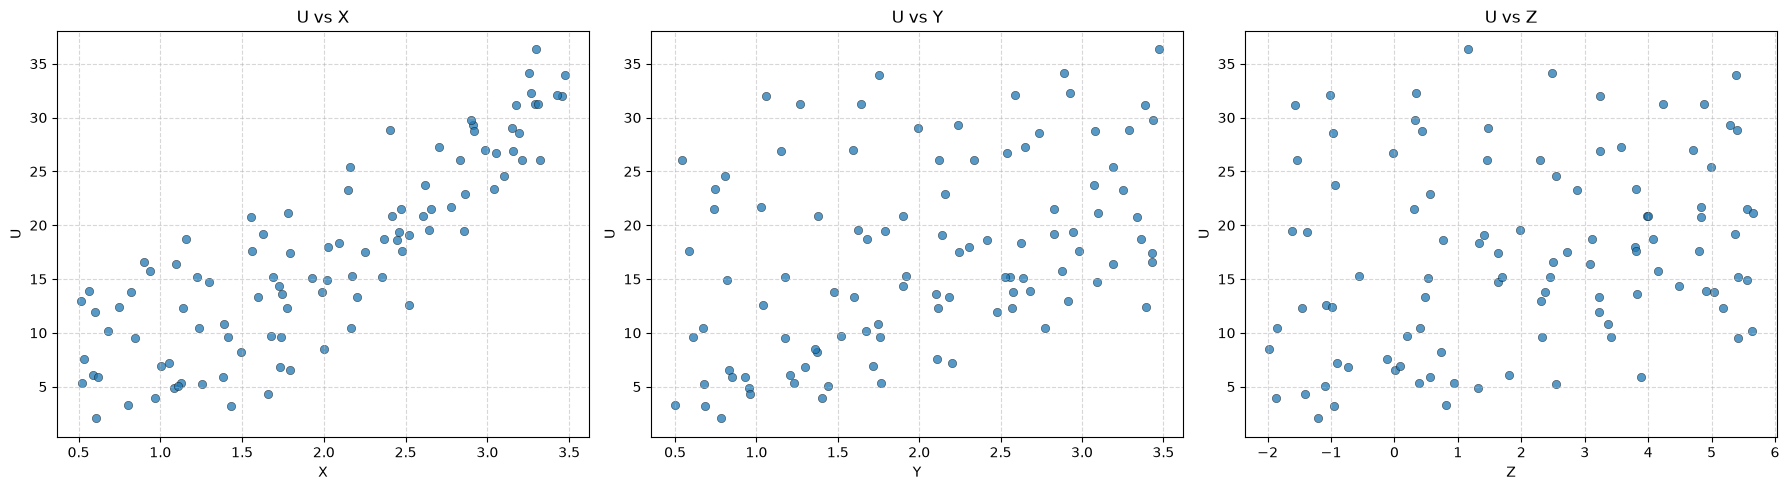

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_specs = [
    ("x", "U vs X", "X", "U"),
    ("y", "U vs Y", "Y", "U"),
    ("z", "U vs Z", "Z", "U"),
]

for ax, (column, title, x_label, y_label) in zip(axes, plot_specs):
    ax.scatter(df[column], df["u"], alpha=0.75, edgecolors="black", linewidths=0.35)
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

<div dir="rtl">

### 2.1T — توصیف روند رابطه‌ی خروجی با هر ورودی

- **رابطه‌ی `u` و `x`:** با افزایش `x`، خروجی عموماً افزایش می‌یابد و الگوی نقاط انحنادار است؛ بنابراین رابطه‌ی احتمالی مثبت و غیرخطی به نظر می‌رسد. فاصله‌ی نقاط از یک منحنی ایده‌آل را می‌توان با نویز و اثر هم‌زمان ورودی‌های دیگر توضیح داد.
- **رابطه‌ی `u` و `y`:** روند کلی مثبت است، اما پراکندگی نقاط نشان می‌دهد `y` به‌تنهایی تمام تغییرات خروجی را توضیح نمی‌دهد. شکل رابطه ممکن است نسبت به `x` ملایم‌تر باشد.
- **رابطه‌ی `u` و `z`:** در نمودار خام ممکن است اثر `z` به‌علت پراکندگی و اثر ورودی‌های دیگر به‌وضوح دیده نشود. برای قضاوت بهتر باید دو ورودی دیگر را ثابت نگه داشت و اثر کنترل‌شده‌ی `z` را بررسی کرد؛ این کار در بخش ۷ و بخش امتیازی انجام می‌شود.

نمودار پراکنش شواهد اولیه فراهم می‌کند، اما به‌تنهایی شکل دقیق تابع یا سهم مستقل هر ویژگی را اثبات نمی‌کند. در نتیجه‌گیری نهایی باید نمودارها را همراه با پیش‌بینی‌های مدل و تحلیل کنترل‌شده تفسیر کرد.

### 2.2T — چرا همبستگی به معنی رابطه‌ی علّی نیست؟

همبستگی فقط نشان می‌دهد دو متغیر در داده‌ها با هم تغییر می‌کنند؛ این الگو ممکن است ناشی از یک متغیر سوم، اثر متقابل چند ویژگی، نحوه‌ی نمونه‌گیری یا تصادف باشد. برای اثبات علیت به طراحی آزمایش یا شواهد علّی مستقل نیاز است. بنابراین از نمودارهای این پروژه می‌توان درباره‌ی ارتباط آماری و روندها فرضیه ساخت، اما نباید نتیجه گرفت که تغییر یک ورودی الزاماً علت مستقیم تغییر خروجی است.

</div>

<div dir="rtl">

## بخش ۳: تقسیم داده و پیش‌پردازش

### 3.1 — تقسیم مستقیم داده به Training، Validation و Test

ابتدا دقیقاً ۷۰٪ داده برای Training جدا می‌شود. سپس ۳۰٪ باقی‌مانده به دو قسمت مساوی تقسیم می‌شود؛ بنابراین Validation و Test هرکدام دقیقاً ۱۵٪ کل داده خواهند بود. برای ۱۰۰ نمونه، اندازه‌ی سه مجموعه به‌ترتیب ۷۰، ۱۵ و ۱۵ است. این روش مستقیماً نسبت نهایی ۷۰/۱۵/۱۵ را می‌سازد و از محاسبه‌ی نسبت Validation بر پایه‌ی ۸۵٪ داده‌ی باقی‌مانده استفاده نمی‌کند.

</div>

In [10]:
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X_all,
    y_all,
    train_size=0.70,
    random_state=SEED,
)

X_val, X_test, y_val, y_test = train_test_split(
    X_holdout,
    y_holdout,
    test_size=0.50,
    random_state=SEED + 1,
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))
print(
    "Split percentages:",
    f"{100 * len(X_train) / len(df):.1f}%",
    f"{100 * len(X_val) / len(df):.1f}%",
    f"{100 * len(X_test) / len(df):.1f}%",
)

assert (len(X_train), len(X_val), len(X_test)) == (70, 15, 15)
assert len(X_train) + len(X_val) + len(X_test) == len(df)

Training samples: 70
Validation samples: 15
Test samples: 15
Split percentages: 70.0% 15.0% 15.0%


<div dir="rtl">

### 3.2 — استانداردسازی ورودی‌ها و خروجی

</div>

In [11]:
scaler_x = StandardScaler()
X_train_scaled = scaler_x.fit_transform(X_train)
X_val_scaled = scaler_x.transform(X_val)
X_test_scaled = scaler_x.transform(X_test)

scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train).astype(np.float32)
y_val_scaled = scaler_y.transform(y_val).astype(np.float32)
y_test_scaled = scaler_y.transform(y_test).astype(np.float32)

print("Scaled X training mean:", np.round(X_train_scaled.mean(axis=0), 6))
print("Scaled X training std:", np.round(X_train_scaled.std(axis=0), 6))
print("Scaled y training mean:", np.round(y_train_scaled.mean(axis=0), 6))
print("Scaled y training std:", np.round(y_train_scaled.std(axis=0), 6))

Scaled X training mean: [-0.  0.  0.]
Scaled X training std: [1. 1. 1.]
Scaled y training mean: [-0.]
Scaled y training std: [1.]


<div dir="rtl">

### 3.1T — نقش سه مجموعه‌ی Training، Validation و Test

- **Training:** برای محاسبه‌ی گرادیان‌ها و به‌روزرسانی وزن‌ها استفاده می‌شود؛ مدل مستقیماً از این نمونه‌ها یاد می‌گیرد.
- **Validation:** برای مقایسه‌ی پیکربندی‌ها، انتخاب ابرپارامترها، پایش روند آموزش و انتخاب مدل نهایی استفاده می‌شود. وزن‌ها با این مجموعه مستقیماً آموزش داده نمی‌شوند.
- **Test:** فقط پس از تثبیت مدل نهایی برای برآورد عملکرد روی داده‌های دیده‌نشده استفاده می‌شود. نتیجه‌ی Test نباید دوباره مبنای تنظیم معماری یا ابرپارامترها قرار گیرد.

اگر Test در انتخاب مدل دخالت داده شود، دیگر یک ارزیابی مستقل از فرایند انتخاب نخواهد بود. وجود هر سه مجموعه به تفکیک یادگیری، انتخاب مدل و ارزیابی نهایی کمک می‌کند.

### 3.2T — نشت داده (Data Leakage)

نشت داده زمانی رخ می‌دهد که اطلاعاتی از داده‌های خارج از مجموعه‌ی مجاز آموزش، مستقیم یا غیرمستقیم وارد فرایند یادگیری یا انتخاب مدل شود. اگر میانگین و انحراف معیار استانداردسازی را با کل داده محاسبه کنیم، اطلاعات توزیع Validation و Test به مرحله‌ی پیش‌پردازش آموزش راه پیدا می‌کند. در این حالت مدل یا روند انتخاب آن به اطلاعاتی دسترسی پیدا می‌کند که در سناریوی واقعیِ داده‌ی جدید در اختیارش نیست؛ در نتیجه عملکرد گزارش‌شده می‌تواند خوش‌بینانه و برآورد تعمیم‌پذیری غیرواقعی باشد. راه درست این است که `fit` فقط روی Training اجرا شود و سپس همان تبدیل روی Validation و Test با `transform` اعمال گردد.

</div>

<div dir="rtl">

## بخش ۴: طراحی آزمایش‌های ابرپارامتر

### 4.1 — تعریف دست‌کم پنج پیکربندی متفاوت

پیکربندی‌ها از نظر تعداد لایه‌های مخفی، تعداد نورون‌ها، تابع فعال‌سازی، نرخ یادگیری و اندازه‌ی دسته متفاوت‌اند. برای مقایسه‌ی منصفانه، تقسیم داده و معیار انتخاب مدل در تمام آزمایش‌ها ثابت می‌ماند.

</div>

In [12]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(SEED)
print("TensorFlow version:", tf.__version__)

configs = [
    {"config_id": 1, "hidden_layers": [16], "activation": "relu", "learning_rate": 0.010, "batch_size": 16},
    {"config_id": 2, "hidden_layers": [32, 16], "activation": "relu", "learning_rate": 0.001, "batch_size": 32},
    {"config_id": 3, "hidden_layers": [64, 32], "activation": "tanh", "learning_rate": 0.010, "batch_size": 16},
    {"config_id": 4, "hidden_layers": [32], "activation": "tanh", "learning_rate": 0.005, "batch_size": 32},
    {"config_id": 5, "hidden_layers": [16, 8, 4], "activation": "relu", "learning_rate": 0.001, "batch_size": 8},
]

config_table = pd.DataFrame(configs)
display(config_table)

assert len(configs) >= 5
assert len({tuple(config["hidden_layers"]) for config in configs}) >= 3
assert len({config["activation"] for config in configs}) >= 2

TensorFlow version: 2.22.0-rc0


,config_id,hidden_layers,activation,learning_rate,batch_size
0,1,[16],relu,0.010,16
1,2,"[32, 16]",relu,0.001,32
2,3,"[64, 32]",tanh,0.010,16
3,4,[32],tanh,0.005,32
4,5,"[16, 8, 4]",relu,0.001,8


<div dir="rtl">

### 4.2 — بررسی تنوع معماری‌ها و توابع فعال‌سازی

در جدول پیکربندی‌ها حداقل سه ساختار لایه‌ی مخفی و دو تابع فعال‌سازی متفاوت وجود دارد. نرخ یادگیری و اندازه‌ی دسته نیز در چند آزمایش تغییر کرده‌اند.

### 4.3 — ثبت مشخصات و معیار Validation هر آزمایش

جدول پیکربندی‌ها شامل شناسه، ساختار لایه‌های مخفی، تابع فعال‌سازی، نرخ یادگیری و اندازه‌ی دسته است. جدول نتایج پس از آموزش، تعداد Epoch اجراشده و معیارهای ثابت Validation RMSE و Validation MAE را نیز به آن اضافه می‌کند.

</div>

<div dir="rtl">

### 4.1T — مقایسه‌ی ReLU و tanh

تابع **ReLU** به‌صورت \(f(x)=\max(0,x)\) تعریف می‌شود. برای ورودی مثبت مشتق آن یک است و برای ورودی منفی مشتق صفر دارد. سادگی محاسبات و نداشتن اشباع در ناحیه‌ی مثبت، معمولاً آموزش شبکه‌های عمیق را آسان‌تر می‌کند؛ البته ممکن است بعضی نورون‌ها در ناحیه‌ی منفی غیرفعال بمانند.

تابع **tanh** خروجی را در بازه‌ی \([-1,1]\) قرار می‌دهد و حول صفر متقارن است. وقتی قدرمطلق ورودی بسیار بزرگ شود، خروجی به حدود مثبت یا منفی یک نزدیک می‌شود و مشتق آن کوچک خواهد شد؛ این اشباع می‌تواند گرادیان را تضعیف و یادگیری را کند کند.

هیچ‌کدام در همه‌ی مسائل برتر نیستند. در این مسئله باید به جدول Validation نگاه کرد: پیکربندی منتخب، پیکربندی‌ای است که کمترین Validation RMSE را دارد. اگر پیکربندی‌های ReLU خطای کمتری داشته باشند، فقط در همین داده، معماری و تنظیمات عملکرد بهتری نشان داده‌اند؛ همین قاعده برای tanh نیز برقرار است. مقیاس‌بندی ورودی‌ها و خروجی نیز روی رفتار این توابع اثر می‌گذارد.

### 4.2T — چرا لایه‌ی خروجی خطی است؟

این مسئله رگرسیون است و خروجی `u` یک مقدار پیوسته است که محدود به بازه‌ی صفر تا یک نیست. تابع خطی \(f(x)=x\) خروجی را به بازه‌ی محدودی محدود نمی‌کند و اجازه می‌دهد مدل مقادیر مثبت، منفی یا بزرگ‌تر از یک را پیش‌بینی کند. در مقابل، `sigmoid` خروجی را به بازه‌ی \((0,1)\) محدود می‌کند و `ReLU` اجازه‌ی خروجی منفی نمی‌دهد؛ این محدودیت‌ها ممکن است با دامنه‌ی واقعی `u` ناسازگار باشند. بنابراین برای نورون خروجی از فعال‌سازی خطی استفاده می‌کنیم.

</div>

<div dir="rtl">

## بخش ۵: آموزش و انتخاب MLP

### 5.1 — ساخت MLP برای مسئله‌ی رگرسیون

برای هر پیکربندی، مدل با سه ویژگی ورودی، لایه‌های مخفی مشخص‌شده و یک نورون خروجی با فعال‌سازی خطی ساخته می‌شود.

### 5.2 — آموزش تا حداکثر ۱۰۰ Epoch و استفاده از Early Stopping

مدل‌ها با داده‌ی Training آموزش می‌بینند و عملکرد هر Epoch روی Validation پایش می‌شود. توقف زودهنگام در صورت نبود بهبود در `val_loss` پس از ۱۵ Epoch متوالی اجرا می‌شود و وزن‌های بهترین Epoch بازگردانده می‌شوند.

### 5.3 — مقایسه و انتخاب مدل نهایی

پیکربندی‌های اولیه با Validation RMSE در مقیاس اصلی خروجی مقایسه می‌شوند. سپس آزمایش‌های Ablation با تغییر کنترل‌شده‌ی نرخ یادگیری، اندازه‌ی مدل و اندازه‌ی دسته انجام می‌شوند؛ مدل نهایی از نتایج Validation این آزمایش‌ها انتخاب می‌شود. Test در هیچ مرحله‌ی انتخاب مدل استفاده نمی‌شود.

</div>

In [13]:
def build_mlp(hidden_layers, activation):
    model = keras.Sequential(name="mlp_regressor")
    model.add(layers.Input(shape=(X_train_scaled.shape[1],)))
    for units in hidden_layers:
        model.add(layers.Dense(units, activation=activation))
    model.add(layers.Dense(1, activation="linear"))
    return model

results = []
trained_models = {}
training_histories = {}

for config in configs:
    config_id = config["config_id"]
    keras.utils.set_random_seed(SEED + config_id)

    model = build_mlp(config["hidden_layers"], config["activation"])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=config["learning_rate"]),
        loss="mse",
        metrics=["mae"],
    )

    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        # patience=15,
        patience=100,
        restore_best_weights=True,
    )

    history = model.fit(
        X_train_scaled,
        y_train_scaled,
        validation_data=(X_val_scaled, y_val_scaled),
        epochs=100,
        batch_size=config["batch_size"],
        callbacks=[early_stopping],
        verbose=0,
    )

    val_predictions_scaled = model.predict(X_val_scaled, verbose=0)
    val_predictions = scaler_y.inverse_transform(val_predictions_scaled)
    val_rmse = float(np.sqrt(mean_squared_error(y_val, val_predictions)))
    val_mae = float(mean_absolute_error(y_val, val_predictions))

    results.append({
        "config_id": config_id,
        "hidden_layers": str(config["hidden_layers"]),
        "activation": config["activation"],
        "learning_rate": config["learning_rate"],
        "batch_size": config["batch_size"],
        "epochs_run": len(history.epoch),
        "best_val_loss_scaled": float(np.min(history.history["val_loss"])),
        "validation_RMSE": val_rmse,
        "validation_MAE": val_mae,
    })
    trained_models[config_id] = model
    training_histories[config_id] = history

results_df = pd.DataFrame(results).sort_values("validation_RMSE").reset_index(drop=True)
print("Model comparison on the Validation set:")
display(results_df)

best_config_id = int(results_df.loc[0, "config_id"])
best_config = next(config for config in configs if config["config_id"] == best_config_id)
best_model = trained_models[best_config_id]
best_history = training_histories[best_config_id]

print("Selected configuration:", best_config_id)
print("Selected hidden layers:", best_config["hidden_layers"])
print("Selected activation:", best_config["activation"])
print("Selected validation RMSE:", float(results_df.loc[0, "validation_RMSE"]))

Model comparison on the Validation set:


,config_id,hidden_layers,activation,learning_rate,batch_size,epochs_run,best_val_loss_scaled,validation_RMSE,validation_MAE
0,3,"[64, 32]",tanh,0.010,16,100,0.002564,0.456670,0.373516
1,1,[16],relu,0.010,16,100,0.005239,0.652785,0.560290
2,2,"[32, 16]",relu,0.001,32,100,0.020274,1.284169,1.009292
3,4,[32],tanh,0.005,32,100,0.030024,1.562752,1.373093
4,5,"[16, 8, 4]",relu,0.001,8,100,0.123286,3.166744,1.977051


Selected configuration: 3
Selected hidden layers: [64, 32]
Selected activation: tanh
Selected validation RMSE: 0.4566700478008615


<div dir="rtl">

### آزمایش‌های کنترل‌شده‌ی ابرپارامترها (Ablation Study)

در سه آزمایش نخست، تابع فعال‌سازی ثابت و برابر **tanh** است تا اثر نرخ یادگیری، اندازه‌ی مدل و اندازه‌ی دسته جداگانه بررسی شود. در هر مرحله فقط پارامتر نام‌برده تغییر می‌کند و بهترین مقدار Validation به مرحله‌ی بعد منتقل می‌شود. هر نمودار مقیاس عمودی مستقل دارد؛ بنابراین یک آزمایش ناپایدار یا با خطای بسیار بزرگ، منحنی‌های سایر آزمایش‌ها را فشرده نمی‌کند.

در مرحله‌ی چهارم، دو مدل با معماری، نرخ یادگیری، اندازه‌ی دسته، داده و مقداردهی اولیه‌ی کاملاً یکسان مقایسه می‌شوند؛ تنها تفاوت آن‌ها تابع فعال‌سازی است: یکی `ReLU` و دیگری `tanh`. این مرحله مشخص می‌کند آیا تغییر تابع فعال‌سازی نسبت به مبنای tanh بهبود ایجاد می‌کند یا نه. مدل نهایی با Validation RMSE انتخاب می‌شود و همان مدل برای بخش‌های بعدی استفاده خواهد شد.

</div>

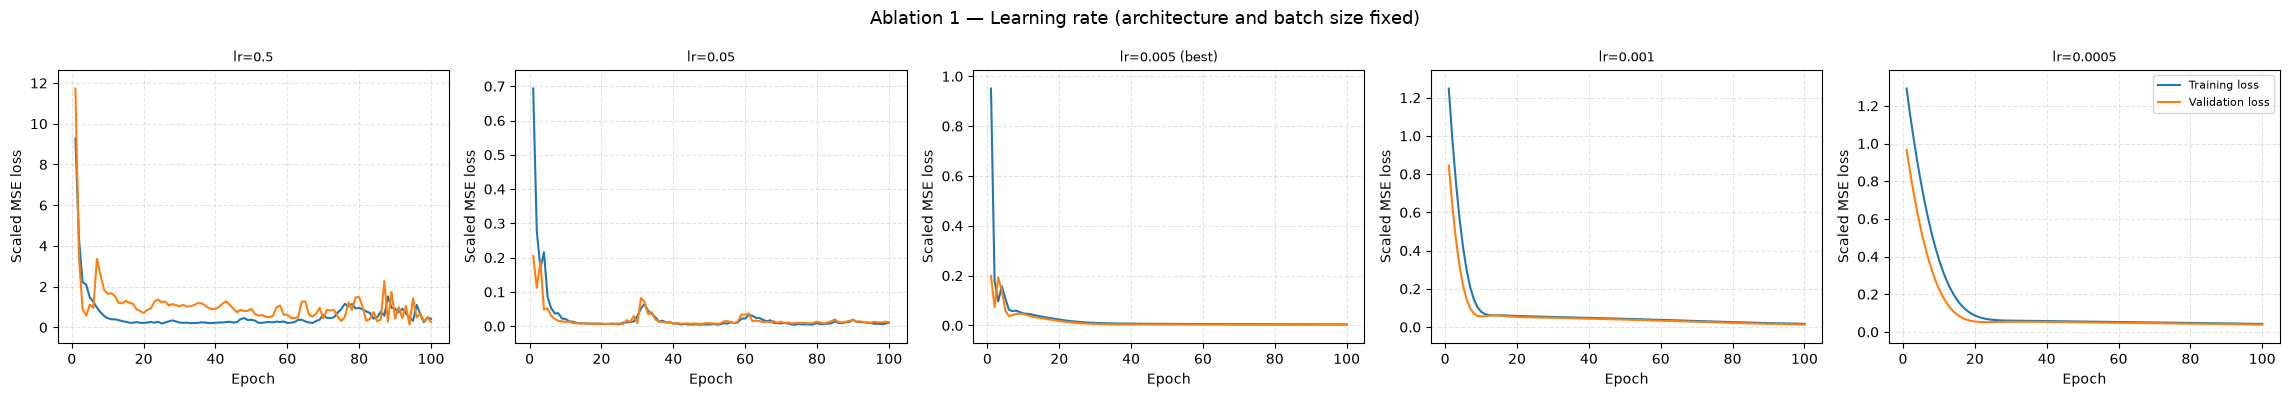

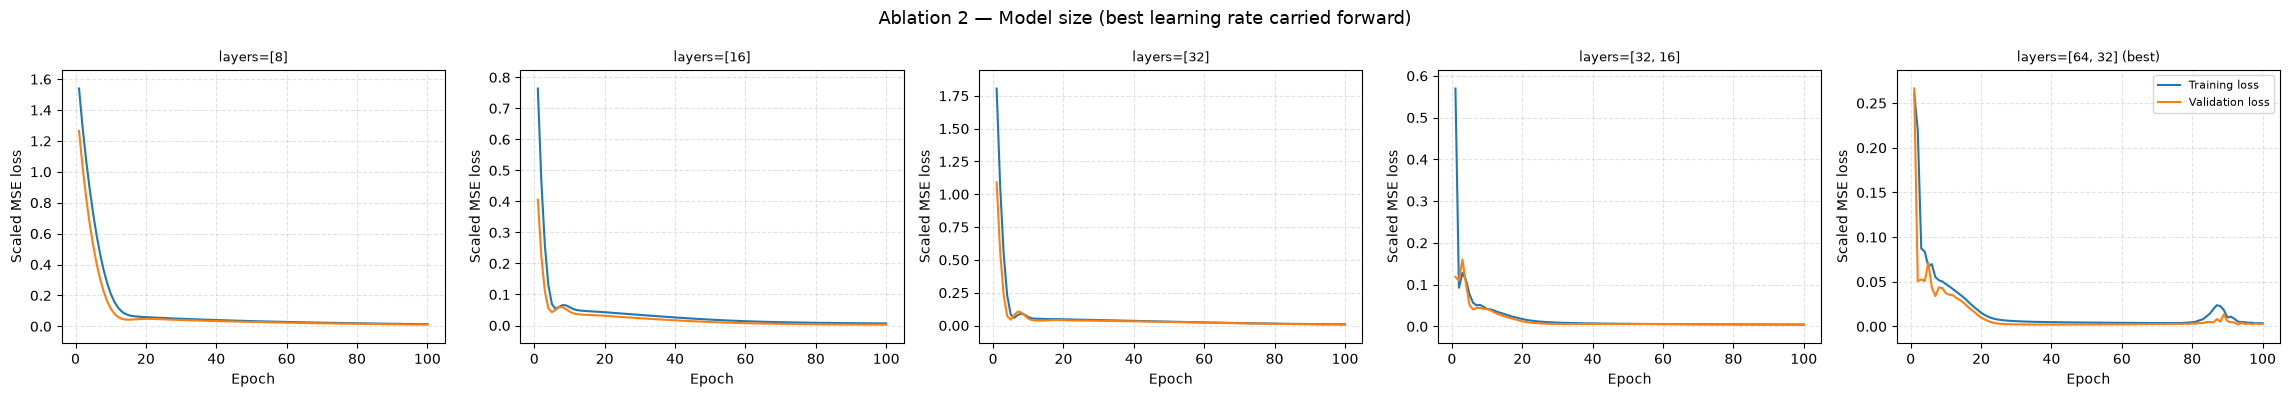

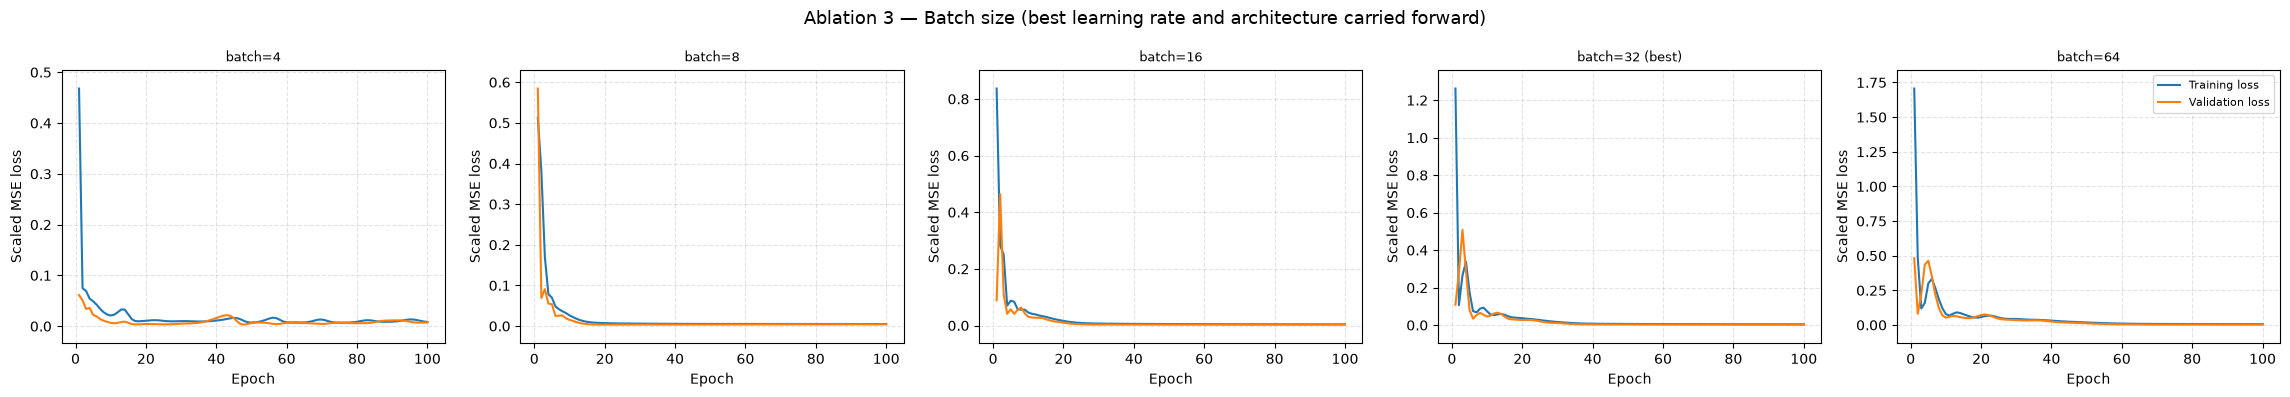

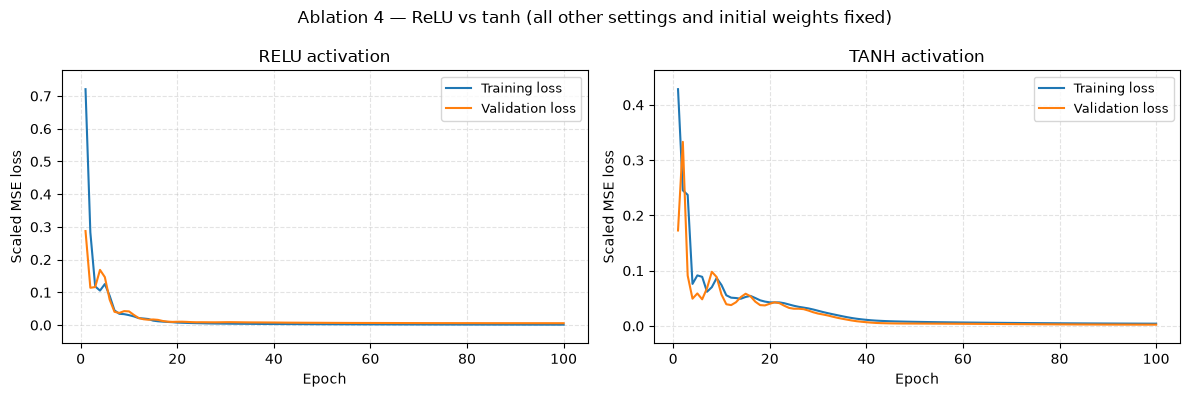

Controlled ablation results (lower Validation RMSE is better):


,stage,varied_setting,hidden_layers,activation,learning_rate,batch_size,epochs_run,best_validation_MSE_scaled,validation_RMSE
0,Learning rate,lr=0.5,"[32, 16]",tanh,0.5000,16,100,0.134313,3.305333
1,Learning rate,lr=0.05,"[32, 16]",tanh,0.0500,16,100,0.005665,0.678813
2,Learning rate,lr=0.005,"[32, 16]",tanh,0.0050,16,100,0.003527,0.535645
3,Learning rate,lr=0.001,"[32, 16]",tanh,0.0010,16,100,0.012733,1.017693
4,Learning rate,lr=0.0005,"[32, 16]",tanh,0.0005,16,100,0.038632,1.772679
5,Model size,layers=[8],[8],tanh,0.0050,16,100,0.011209,0.954844
6,Model size,layers=[16],[16],tanh,0.0050,16,100,0.002937,0.488759
7,Model size,layers=[32],[32],tanh,0.0050,16,100,0.006969,0.752912
8,Model size,"layers=[32, 16]","[32, 16]",tanh,0.0050,16,100,0.004695,0.617988
9,Model size,"layers=[64, 32]","[64, 32]",tanh,0.0050,16,100,0.002082,0.411535


Final ablation-selected configuration:
{'hidden_layers': [64, 32], 'activation': 'tanh', 'learning_rate': 0.005, 'batch_size': 32}
Final Validation RMSE: 0.439871


In [15]:
ABLATION_BASE_ACTIVATION = "tanh"

def run_ablation_candidate(run_name, hidden_layers, learning_rate, batch_size, stage_seed, activation=ABLATION_BASE_ACTIVATION):
    keras.utils.set_random_seed(SEED + stage_seed)

    model = build_mlp(hidden_layers, activation)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="mse",
        metrics=["mae"],
    )

    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            # patience=15,
            patience=100,
            restore_best_weights=True,
        ),
        keras.callbacks.TerminateOnNaN(),
    ]

    history = model.fit(
        X_train_scaled,
        y_train_scaled,
        validation_data=(X_val_scaled, y_val_scaled),
        epochs=100,
        batch_size=batch_size,
        callbacks=callbacks,
        verbose=0,
    )

    val_predictions_scaled = model.predict(X_val_scaled, verbose=0)
    val_predictions = scaler_y.inverse_transform(val_predictions_scaled)
    val_rmse = (
        float(np.sqrt(mean_squared_error(y_val, val_predictions)))
        if np.isfinite(val_predictions).all()
        else float("inf")
    )

    finite_val_losses = [
        float(value)
        for value in history.history.get("val_loss", [])
        if np.isfinite(value)
    ]
    best_val_loss = min(finite_val_losses) if finite_val_losses else float("inf")

    return {
        "run_name": run_name,
        "hidden_layers": list(hidden_layers),
        "activation": activation,
        "learning_rate": float(learning_rate),
        "batch_size": int(batch_size),
        "epochs_run": len(history.epoch),
        "best_val_loss_scaled": best_val_loss,
        "validation_RMSE": val_rmse,
        "model": model,
        "history": history,
    }


def choose_best_ablation(runs, stage_name):
    valid_runs = [run for run in runs if np.isfinite(run["validation_RMSE"])]
    if not valid_runs:
        raise RuntimeError(
            f"All {stage_name} candidates produced non-finite Validation predictions."
        )
    return min(valid_runs, key=lambda run: run["validation_RMSE"])


def plot_ablation_group(runs, stage_title, best_run):
    # Every candidate gets its own y-axis limits so a divergent run cannot flatten the other curves.
    fig, axes = plt.subplots(1, 5, figsize=(23, 4), sharey=False)

    for ax, run in zip(axes, runs):
        epochs = np.arange(1, len(run["history"].history["loss"]) + 1)
        ax.plot(epochs, run["history"].history["loss"], label="Training loss")
        ax.plot(epochs, run["history"].history["val_loss"], label="Validation loss")
        suffix = " (best)" if run["run_name"] == best_run["run_name"] else ""
        ax.set_title(run["run_name"] + suffix, fontsize=9)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Scaled MSE loss")
        ax.grid(True, linestyle="--", alpha=0.35)
        ax.margins(y=0.08)

    axes[-1].legend(fontsize=8)
    fig.suptitle(stage_title, fontsize=13)
    plt.tight_layout()
    plt.show()


# Start from a deliberate baseline. Each sweep changes only its named parameter.
current_hidden_layers = [32, 16]
current_learning_rate = 0.005
current_batch_size = 16
current_activation = ABLATION_BASE_ACTIVATION

# Stage 1: learning rate. The other hyperparameters remain at their baseline values.
learning_rate_values = [0.5, 0.05, 0.005, 0.001, 0.0005]
learning_rate_runs = [
    run_ablation_candidate(
        run_name=f"lr={value:g}",
        hidden_layers=current_hidden_layers,
        learning_rate=value,
        batch_size=current_batch_size,
        stage_seed=4100,
    )
    for value in learning_rate_values
]
best_learning_rate_run = choose_best_ablation(learning_rate_runs, "learning-rate")
current_learning_rate = best_learning_rate_run["learning_rate"]
plot_ablation_group(
    learning_rate_runs,
    "Ablation 1 — Learning rate (architecture and batch size fixed)",
    best_learning_rate_run,
)

# Stage 2: model size. Carry the best learning rate from Stage 1 into every run.
model_size_candidates = [[8], [16], [32], [32, 16], [64, 32]]
model_size_runs = [
    run_ablation_candidate(
        run_name=f"layers={architecture}",
        hidden_layers=architecture,
        learning_rate=current_learning_rate,
        batch_size=current_batch_size,
        stage_seed=4200,
    )
    for architecture in model_size_candidates
]
best_model_size_run = choose_best_ablation(model_size_runs, "model-size")
current_hidden_layers = best_model_size_run["hidden_layers"]
plot_ablation_group(
    model_size_runs,
    "Ablation 2 — Model size (best learning rate carried forward)",
    best_model_size_run,
)

# Stage 3: batch size. Carry the best learning rate and architecture forward.
batch_size_values = [4, 8, 16, 32, 64]
batch_size_runs = [
    run_ablation_candidate(
        run_name=f"batch={value}",
        hidden_layers=current_hidden_layers,
        learning_rate=current_learning_rate,
        batch_size=value,
        stage_seed=4300,
    )
    for value in batch_size_values
]
best_batch_size_run = choose_best_ablation(batch_size_runs, "batch-size")
current_batch_size = best_batch_size_run["batch_size"]
plot_ablation_group(
    batch_size_runs,
    "Ablation 3 — Batch size (best learning rate and architecture carried forward)",
    best_batch_size_run,
)

# Stage 4: activation function. All selected hyperparameters and starting weights are identical.
def run_activation_candidate(activation, shared_seed, initial_weights=None):
    keras.utils.set_random_seed(SEED + shared_seed)
    model = build_mlp(current_hidden_layers, activation)
    if initial_weights is not None:
        model.set_weights(initial_weights)
    starting_weights = [weight.copy() for weight in model.get_weights()]
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=current_learning_rate),
        loss="mse",
        metrics=["mae"],
    )
    history = model.fit(
        X_train_scaled,
        y_train_scaled,
        validation_data=(X_val_scaled, y_val_scaled),
        epochs=100,
        batch_size=current_batch_size,
        callbacks=[
            keras.callbacks.EarlyStopping(
                monitor="val_loss",
                # patience=15,
                patience=100,
                restore_best_weights=True,
            ),
            keras.callbacks.TerminateOnNaN(),
        ],
        verbose=0,
    )

    predictions_scaled = model.predict(X_val_scaled, verbose=0)
    predictions = scaler_y.inverse_transform(predictions_scaled)
    val_rmse = (
        float(np.sqrt(mean_squared_error(y_val, predictions)))
        if np.isfinite(predictions).all()
        else float("inf")
    )
    return {
        "run_name": activation,
        "activation": activation,
        "hidden_layers": list(current_hidden_layers),
        "learning_rate": float(current_learning_rate),
        "batch_size": int(current_batch_size),
        "epochs_run": len(history.epoch),
        "best_val_loss_scaled": float(np.nanmin(history.history["val_loss"])),
        "validation_RMSE": val_rmse,
        "model": model,
        "history": history,
        "initial_weights": starting_weights,
    }


activation_shared_seed = 4400
relu_activation_run = run_activation_candidate("relu", activation_shared_seed)
tanh_activation_run = run_activation_candidate(
    "tanh",
    activation_shared_seed,
    initial_weights=relu_activation_run["initial_weights"],
)
activation_runs = [relu_activation_run, tanh_activation_run]

# Both models are explicitly assigned identical starting weights; activation is the only changed variable.
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, run in zip(axes, activation_runs):
    epochs = np.arange(1, len(run["history"].history["loss"]) + 1)
    ax.plot(epochs, run["history"].history["loss"], label="Training loss")
    ax.plot(epochs, run["history"].history["val_loss"], label="Validation loss")
    ax.set_title(f'{run["activation"].upper()} activation')
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Scaled MSE loss")
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.margins(y=0.08)
    ax.legend(fontsize=9)
plt.suptitle("Ablation 4 — ReLU vs tanh (all other settings and initial weights fixed)")
plt.tight_layout()
plt.show()

best_activation_run = choose_best_ablation(activation_runs, "activation")
current_activation = best_activation_run["activation"]
activation_models_100 = {
    run["activation"]: run["model"] for run in activation_runs
}
activation_histories_100 = {
    run["activation"]: run["history"] for run in activation_runs
}

all_ablation_runs = (
    learning_rate_runs + model_size_runs + batch_size_runs + activation_runs
)
ablation_summary = pd.DataFrame([
    {
        "stage": stage,
        "varied_setting": run["run_name"],
        "hidden_layers": str(run["hidden_layers"]),
        "activation": run["activation"],
        "learning_rate": run["learning_rate"],
        "batch_size": run["batch_size"],
        "epochs_run": run["epochs_run"],
        "best_validation_MSE_scaled": run["best_val_loss_scaled"],
        "validation_RMSE": run["validation_RMSE"],
    }
    for stage, runs in [
        ("Learning rate", learning_rate_runs),
        ("Model size", model_size_runs),
        ("Batch size", batch_size_runs),
        ("Activation", activation_runs),
    ]
    for run in runs
])
print("Controlled ablation results (lower Validation RMSE is better):")
display(ablation_summary)

# The final model is selected from Validation after all four ablation stages.
best_config = {
    "hidden_layers": current_hidden_layers,
    "activation": current_activation,
    "learning_rate": current_learning_rate,
    "batch_size": current_batch_size,
}
best_config_id = "Ablation-selected"
best_model = best_activation_run["model"]
best_history = best_activation_run["history"]

print("Final ablation-selected configuration:")
print(best_config)
print(f"Final Validation RMSE: {best_activation_run['validation_RMSE']:.6f}")


<div dir="rtl">

### 5.1T — معماری واقعی مدل منتخب و محاسبه‌ی شکل وزن‌ها و تعداد پارامترها

</div>

In [ ]:
print("Selected model summary:")
best_model.summary()

parameter_rows = []
input_units = X_train_scaled.shape[1]
for layer in best_model.layers:
    if isinstance(layer, layers.Dense):
        output_units = int(layer.units)
        kernel_shape = tuple(int(value) for value in layer.kernel.shape)
        bias_shape = tuple(int(value) for value in layer.bias.shape)
        kernel_parameters = int(np.prod(kernel_shape))
        bias_parameters = int(np.prod(bias_shape))
        parameter_rows.append({
            "layer": layer.name,
            "input_units": input_units,
            "output_units": output_units,
            "kernel_shape": str(kernel_shape),
            "bias_shape": str(bias_shape),
            "kernel_parameters": kernel_parameters,
            "bias_parameters": bias_parameters,
            "total_parameters": kernel_parameters + bias_parameters,
        })
        input_units = output_units

parameter_df = pd.DataFrame(parameter_rows)
display(parameter_df)

manual_parameter_total = int(parameter_df["total_parameters"].sum())
keras_parameter_total = int(np.sum([np.prod(variable.shape) for variable in best_model.trainable_variables]))
print("Total trainable parameters (manual):", manual_parameter_total)
print("Total trainable parameters (Keras):", keras_parameter_total)
print("Input batch shape:", (None, X_train_scaled.shape[1]))
print("Output batch shape:", (None, 1))

assert manual_parameter_total == keras_parameter_total

Selected model summary:


Model: "mlp_regressor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_53 (Dense)                │ (None, 32)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_54 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 485 (1.90 KB)

 Trainable params: 161 (644.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 324 (1.27 KB)

,layer,input_units,output_units,kernel_shape,bias_shape,kernel_parameters,bias_parameters,total_parameters
0,dense_53,3,32,"(3, 32)","(32,)",96,32,128
1,dense_54,32,1,"(32, 1)","(1,)",32,1,33


Total trainable parameters (manual): 161
Total trainable parameters (Keras): 161
Input batch shape: (None, 3)
Output batch shape: (None, 1)


<div dir="rtl">

### توضیح نظری 5.1T — تعداد نورون‌ها، شکل وزن‌ها و تعداد پارامترها

در این مسئله سه ویژگی ورودی داریم؛ پس لایه‌ی ورودی سه مقدار دریافت می‌کند. هر لایه‌ی Dense با `n` ورودی و `m` نورون، ماتریس وزن با شکل \((n,m)\) و بردار بایاس با شکل \((m,)\) دارد. بنابراین تعداد پارامترهای قابل‌آموزش آن برابر است با:

\[
\text{parameters}=n\times m+m=(n+1)m
\]

برای مدل منتخب، باید این محاسبه را برای تک‌تک لایه‌ها انجام داد و مجموع گرفت. جدول و خروجی سلول پیشین معماری واقعی برنده‌ی Validation را نشان می‌دهد؛ این مقدار ممکن است با تغییر Seed یا داده‌ی ورودی متفاوت شود. تعداد پارامترها باید با همان معماری گزارش شود، نه با یک پیکربندی آزمایشی دیگر. به‌عنوان نمونه، اگر سه ورودی به ۶۴ نورون متصل شوند، شکل Kernel برابر \((3,64)\)، شکل Bias برابر \((64,)\) و تعداد پارامترها برابر \(3\times64+64=256\) خواهد بود.

### 5.2T — نقش نرخ یادگیری در پس‌انتشار خطا

در روش گرادیان کاهشی، وزن‌ها در جهت مخالف گرادیان تابع خطا به‌روزرسانی می‌شوند:

\[
w_{t+1}=w_t-\eta\nabla_w L
\]

در این رابطه \(\eta\) نرخ یادگیری است و اندازه‌ی گام به‌روزرسانی را تعیین می‌کند. اگر این مقدار بسیار بزرگ باشد، الگوریتم ممکن است از نقطه‌ی کمینه عبور کند، نوسان کند یا حتی واگرا شود. اگر بسیار کوچک باشد، کاهش خطا کند می‌شود و رسیدن به ناحیه‌ی مناسب به زمان زیادی نیاز دارد. بنابراین نرخ یادگیری باید با توجه به رفتار منحنی‌های آموزش و اعتبارسنجی تنظیم شود.

</div>

<div dir="rtl">

## بخش ۶: ارزیابی نهایی

### 6.1 — ارزیابی فقط یک‌بار روی Test پس از انتخاب مدل

پس از انتخاب پیکربندی با Validation، مدل بدون تنظیم مجدد بر اساس Test روی داده‌ی آزمون ارزیابی می‌شود. پیش‌بینی‌ها به مقیاس اصلی `u` برگردانده می‌شوند تا معیارها واحد و تفسیر درست داشته باشند.

</div>

In [ ]:
test_predictions_scaled = best_model.predict(X_test_scaled, verbose=0)
test_predictions = scaler_y.inverse_transform(test_predictions_scaled)

test_mae = float(mean_absolute_error(y_test, test_predictions))
test_mse = float(mean_squared_error(y_test, test_predictions))
test_rmse = float(np.sqrt(test_mse))
test_r2 = float(r2_score(y_test, test_predictions))

print("Final Test metrics:")
print(f"Test MAE:  {test_mae:.6f}")
print(f"Test MSE:  {test_mse:.6f}")
print(f"Test RMSE: {test_rmse:.6f}")
print(f"Test R2:   {test_r2:.6f}")

metric_summary = pd.DataFrame([
    {"metric": "MAE", "value": test_mae},
    {"metric": "MSE", "value": test_mse},
    {"metric": "RMSE", "value": test_rmse},
    {"metric": "R2", "value": test_r2},
])
display(metric_summary)

Final Test metrics:
Test MAE:  1.182566
Test MSE:  1.843673
Test RMSE: 1.357819
Test R2:   0.959949


,metric,value
0,MAE,1.182566
1,MSE,1.843673
2,RMSE,1.357819
3,R2,0.959949


<div dir="rtl">

### 6.2 — نمودار مقدار واقعی در برابر پیش‌بینی‌شده و منحنی خطا

</div>

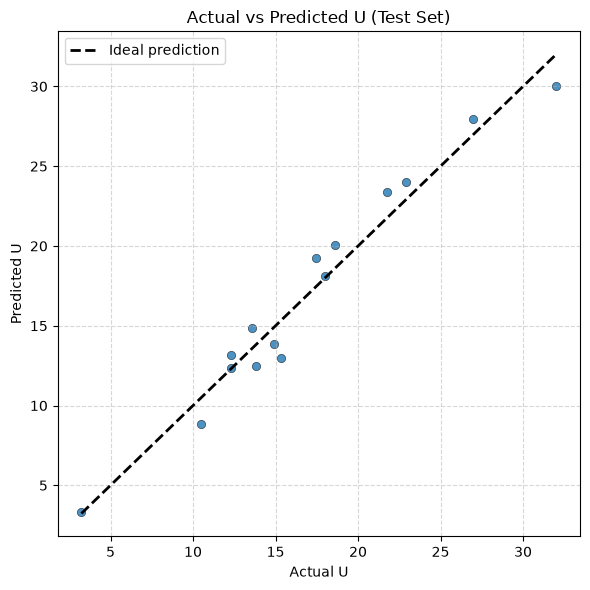

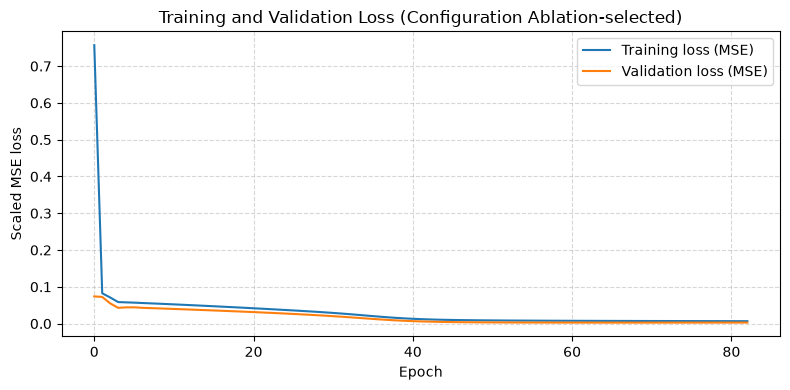

In [ ]:
test_min = float(min(y_test.min(), test_predictions.min()))
test_max = float(max(y_test.max(), test_predictions.max()))

plt.figure(figsize=(6, 6))
plt.scatter(y_test.ravel(), test_predictions.ravel(), alpha=0.8, edgecolors="black", linewidths=0.4)
plt.plot([test_min, test_max], [test_min, test_max], "k--", linewidth=2, label="Ideal prediction")
plt.title("Actual vs Predicted U (Test Set)")
plt.xlabel("Actual U")
plt.ylabel("Predicted U")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(best_history.history["loss"], label="Training loss (MSE)")
plt.plot(best_history.history["val_loss"], label="Validation loss (MSE)")
plt.title(f"Training and Validation Loss (Configuration {best_config_id})")
plt.xlabel("Epoch")
plt.ylabel("Scaled MSE loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

<div dir="rtl">

### 6.1T — مفهوم MAE، MSE و RMSE و تفاوت آن‌ها

- **MAE:** میانگین قدرمطلق اختلاف مقدار واقعی و پیش‌بینی‌شده است. هر نمونه به اندازه‌ی قدرمطلق خطای خود اثر می‌گذارد؛ واحد آن همان واحد `u` است.
- **MSE:** میانگین مربع خطاهاست. به‌علت مجذور کردن خطا، خطاهای بزرگ جریمه‌ی بسیار بیشتری می‌گیرند. واحد آن مربع واحد `u` است.
- **RMSE:** ریشه‌ی دوم MSE است. همچنان نسبت به خطاهای بزرگ حساسیت بیشتری از MAE دارد، اما با گرفتن ریشه، واحد آن دوباره با واحد `u` یکسان می‌شود.

در نتیجه، MAE تفسیر مستقیم‌تری از اندازه‌ی متوسط خطا دارد؛ MSE و RMSE خطاهای بزرگ را شدیدتر جریمه می‌کنند. برای گزارش قابل‌فهم‌تر در مسئله‌ی رگرسیون معمولاً RMSE در کنار MAE ارائه می‌شود.

### 6.2T — تفسیر ضریب تعیین \(R^2\)

\(R^2\) عملکرد مدل را نسبت به پیش‌بینی ساده‌ی میانگین مقادیر هدف مقایسه می‌کند:

\[
R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}
\]

مقدار نزدیک به یک یعنی مدل بخش بزرگی از تغییرات هدف را توضیح می‌دهد. مقدار نزدیک صفر یعنی عملکرد آن تقریباً در حد پیش‌بینی میانگین است. مقدار منفی یعنی مدل روی آن مجموعه حتی از پیش‌بینی ثابت میانگین نیز بدتر عمل کرده است. مقدار \(R^2\) لزوماً درصد دقت مدل نیست و به مجموعه‌ای که روی آن محاسبه می‌شود وابسته است.

### 6.3T — مرتبه‌ی زمانی معیارها

برای `n` نمونه، محاسبه‌ی خطای هر نمونه و جمع‌کردن آن برای MAE و MSE به یک پیمایش روی داده نیاز دارد؛ بنابراین مرتبه‌ی زمانی هر دو \(O(n)\) است. RMSE علاوه بر محاسبه‌ی MSE یک جذر نهایی دارد که نسبت به پیمایش داده هزینه‌ی ناچیزی دارد و مرتبه‌ی زمانی کلی آن همچنان \(O(n)\) است. محاسبه‌ی R² نیز میانگین و دو مجموع مربعات را با یک یا چند پیمایش محاسبه می‌کند و مرتبه‌ی زمانی آن \(O(n)\) است. در این پروژه با فقط ۱۰۰ نمونه، اختلاف عملی زمان محاسبه‌ی این معیارها تعیین‌کننده نیست؛ کیفیت و تفسیر درست آن‌ها اهمیت بیشتری دارد.

</div>

<div dir="rtl">

## بخش ۷: استنتاج رابطه‌ی متغیرها

### 7.1 تا 7.4 — بررسی رابطه‌ی هر ورودی با خروجی و ساخت فرضیه‌ی کلی

برای جدا کردن اثر یک ورودی از اثر دو ورودی دیگر، دو ویژگی را روی میانگین داده‌های Training ثابت می‌کنیم و ویژگی سوم را در محدوده‌ی دیده‌شده‌ی Training تغییر می‌دهیم. این منحنی‌ها اثر کنترل‌شده‌ی مدل را نشان می‌دهند و تفسیر آن‌ها از نمودار خام تک‌متغیره دقیق‌تر است؛ با این حال، همچنان تحلیل مدل هستند و اثبات علیت محسوب نمی‌شوند.

</div>

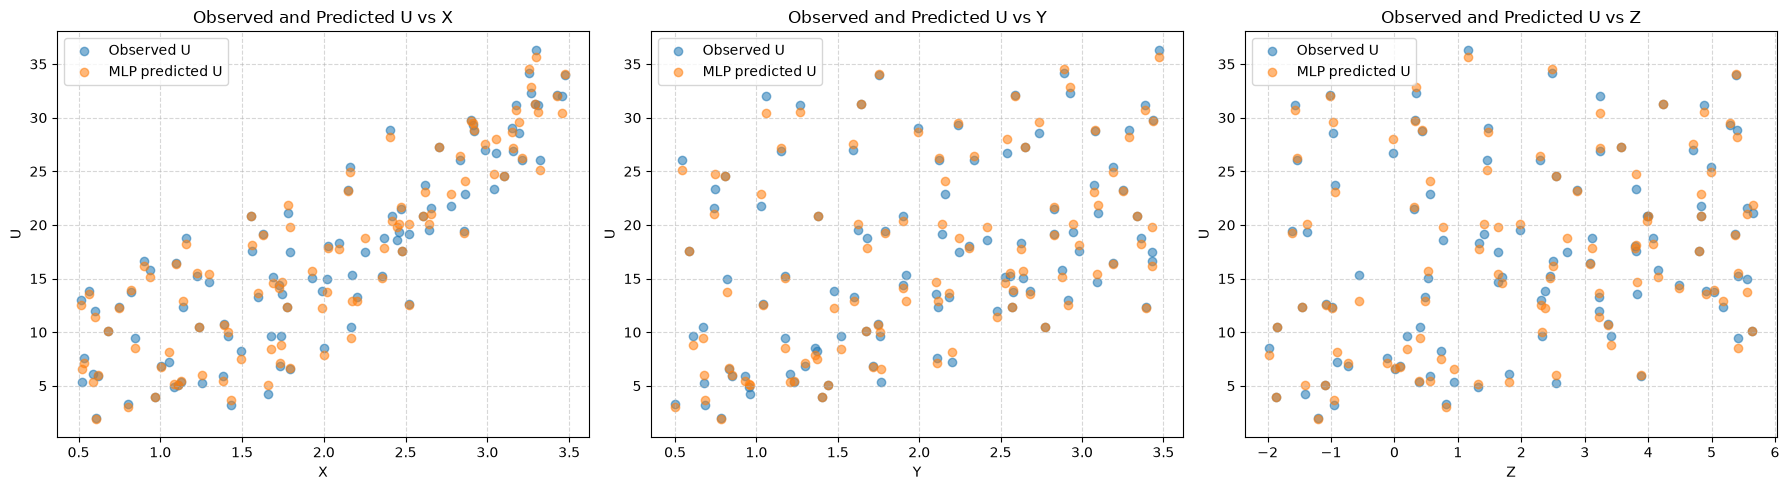

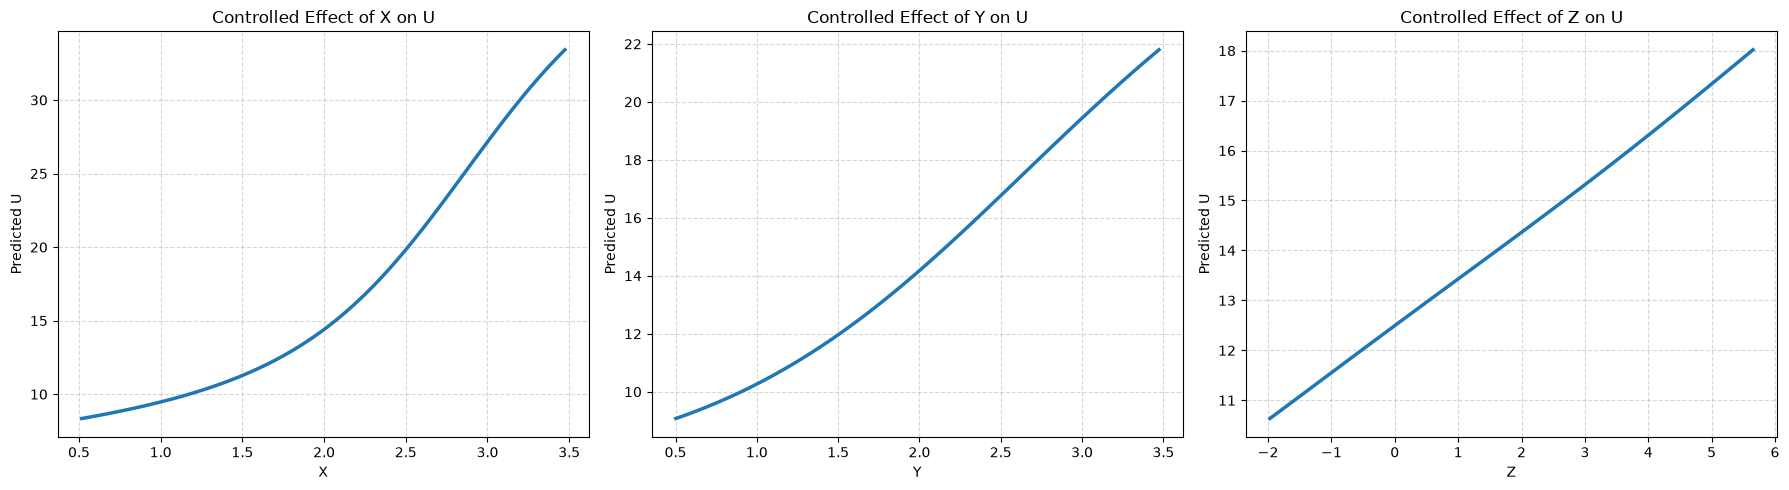

x: fixed other inputs at training means; range [0.5171, 3.4740]
y: fixed other inputs at training means; range [0.5019, 3.4731]
z: fixed other inputs at training means; range [-1.9706, 5.6536]


In [16]:
feature_names = ["x", "y", "z"]
all_predictions_scaled = best_model.predict(scaler_x.transform(X_all), verbose=0)
all_predictions = scaler_y.inverse_transform(all_predictions_scaled).ravel()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for feature_index, feature_name in enumerate(feature_names):
    axes[feature_index].scatter(X_all[:, feature_index], y_all.ravel(), alpha=0.55, label="Observed U")
    axes[feature_index].scatter(X_all[:, feature_index], all_predictions, alpha=0.55, label="MLP predicted U")
    axes[feature_index].set_title(f"Observed and Predicted U vs {feature_name.upper()}")
    axes[feature_index].set_xlabel(feature_name.upper())
    axes[feature_index].set_ylabel("U")
    axes[feature_index].legend()
    axes[feature_index].grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

train_means = X_train.mean(axis=0)
train_minima = X_train.min(axis=0)
train_maxima = X_train.max(axis=0)

controlled_curves = {}
for feature_index, feature_name in enumerate(feature_names):
    feature_values = np.linspace(train_minima[feature_index], train_maxima[feature_index], 100)
    controlled_inputs = np.tile(train_means, (len(feature_values), 1))
    controlled_inputs[:, feature_index] = feature_values

    controlled_inputs_scaled = scaler_x.transform(controlled_inputs)
    controlled_predictions_scaled = best_model.predict(controlled_inputs_scaled, verbose=0)
    controlled_predictions = scaler_y.inverse_transform(controlled_predictions_scaled).ravel()

    controlled_curves[feature_name] = (feature_values, controlled_predictions)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, feature_name in zip(axes, feature_names):
    feature_values, predictions = controlled_curves[feature_name]
    ax.plot(feature_values, predictions, linewidth=2.5)
    ax.set_title(f"Controlled Effect of {feature_name.upper()} on U")
    ax.set_xlabel(feature_name.upper())
    ax.set_ylabel("Predicted U")
    ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

for feature_name in feature_names:
    feature_values, predictions = controlled_curves[feature_name]
    print(
        f"{feature_name}: fixed other inputs at training means; "
        f"range [{feature_values.min():.4f}, {feature_values.max():.4f}]"
    )

<div dir="rtl">

### مقایسه‌ی رابطه‌ی واقعی داده و پاسخ MLP روی ۱۰۰ و ۱۰۰۰ نمونه

رابطه‌ی داده از یک ترکیب افزایشی با دو جمله‌ی توانی و یک جمله‌ی خطی تشکیل شده است:

\[
u = a x^p + b y^q + c z + d + \varepsilon
\]

در این رابطه، اثرهای `x` و `y` با توان‌های قابل‌برآورد مدل می‌شوند؛ اما اثر `z` خطی است و نباید برای آن توان کسری تخمین زد. جمله‌ی ثابت \(d\) برای جذب جابه‌جایی میانگین و جمله‌ی \(\varepsilon\) نویز یا خطای تصادفی داده است.

برای برازش رابطه، ضرایب، توان‌های `x` و `y` و ضریب خطی `z` فقط با داده‌های Training تخمین زده می‌شوند. سپس پاسخ مدل فرمولی و پاسخ MLP با یکدیگر مقایسه می‌شوند. در هر نمودار، دو ورودی دیگر روی میانه‌ی داده‌های Training ثابت‌اند و ورودی سوم در محدوده‌ی Training تغییر می‌کند.

دو MLP با معماری، مقداردهی اولیه، نرخ یادگیری، اندازه‌ی دسته، تعداد Epoch و داده‌های یکسان آموزش داده می‌شوند؛ تنها تفاوت آن‌ها تابع فعال‌سازی لایه‌های مخفی است: یکی `ReLU` و دیگری `tanh`.

این مقایسه جداگانه برای زیرمجموعه‌ی ۱۰۰‌ردیفی و کل ۱۰۰۰ نمونه انجام می‌شود. مدل ۱۰۰۰‌ردیفی از همان ابرپارامترهای منتخب استفاده می‌کند.

</div>

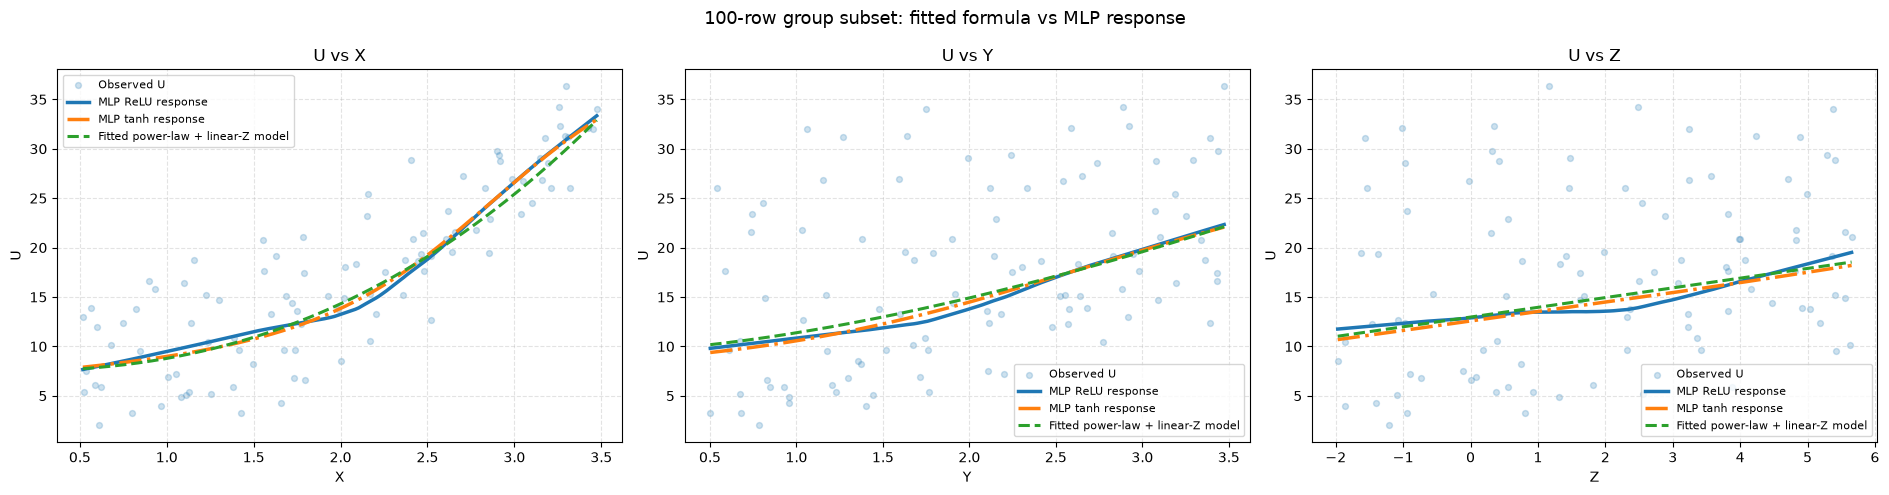

100-row group subset Training-only fitted equation:
u = 1.31717 * x^2.37718 + 1.84001 * y^1.54406 + 0.98447 * z + 0.59393 + epsilon
Epsilon represents the residual noise.
Other two inputs are fixed at their Training medians.
Full-dataset split sizes: 700 150 150


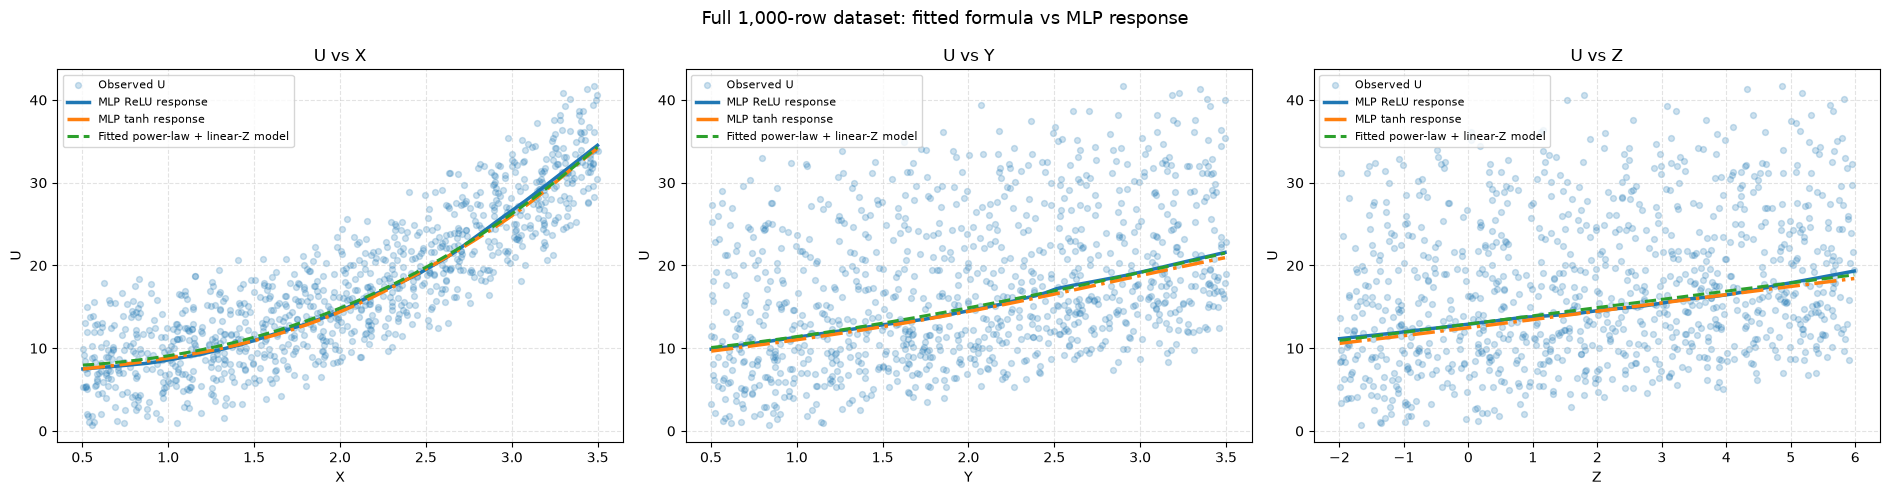

Full 1,000-row dataset Training-only fitted equation:
u = 1.41042 * x^2.34616 + 2.13854 * y^1.39383 + 0.99329 * z + 0.12185 + epsilon
Epsilon represents the residual noise.
Other two inputs are fixed at their Training medians.
Absolute difference between ReLU and tanh controlled responses:


,dataset,feature,mean_absolute_ReLU_tanh_difference,maximum_absolute_ReLU_tanh_difference
0,100-row group subset,x,0.376424,0.853230
1,100-row group subset,y,0.313260,0.805622
2,100-row group subset,z,0.600141,1.316185
3,"Full 1,000-row dataset",x,0.221259,0.627058
4,"Full 1,000-row dataset",y,0.309121,0.637474
5,"Full 1,000-row dataset",z,0.308375,0.902157


100-row Training samples: 70
1,000-row Training samples: 700
The 1,000-row models use the selected 100-row hyperparameters without retuning.


In [17]:
from scipy.optimize import curve_fit


def additive_power_law(inputs, a, p, b, q, c, d):
    x_values, y_values, z_values = inputs
    return (
        a * np.power(x_values, p)
        + b * np.power(y_values, q)
        + c * z_values
        + d
    )


def fit_additive_power_law(training_frame):
    x_values = training_frame["x"].to_numpy(dtype=float)
    y_values = training_frame["y"].to_numpy(dtype=float)
    z_values = training_frame["z"].to_numpy(dtype=float)
    target = training_frame["u"].to_numpy(dtype=float)

    if np.any(x_values <= 0) or np.any(y_values <= 0):
        raise ValueError("The power-law fit requires positive x and y values.")
    if not all(np.isfinite(values).all() for values in
               (x_values, y_values, z_values, target)):
        raise ValueError("Training data contains non-finite values.")

    lower_bounds = [0.0, 0.1, 0.0, 0.1, -np.inf, -np.inf]
    upper_bounds = [np.inf, 5.0, np.inf, 5.0, np.inf, np.inf]
    initial_guesses = [
        [1.5, 2.3, 2.1, 1.4, 1.0, 0.0],
        [1.0, 1.5, 1.0, 1.5, 0.8, 0.0],
        [2.0, 2.0, 2.0, 1.5, 1.2, 0.0],
        [0.5, 1.0, 3.0, 2.0, 1.0, 1.0],
        [1.0, 3.0, 1.0, 1.0, 0.5, -1.0],
    ]

    best_parameters = None
    best_sse = float("inf")

    for initial_guess in initial_guesses:
        try:
            parameters, _ = curve_fit(
                additive_power_law,
                (x_values, y_values, z_values),
                target,
                p0=initial_guess,
                bounds=(lower_bounds, upper_bounds),
                x_scale="jac",
                max_nfev=100000,
            )
            fitted = additive_power_law(
                (x_values, y_values, z_values), *parameters
            )
            sse = float(np.sum((target - fitted) ** 2))
            if np.isfinite(sse) and sse < best_sse:
                best_parameters = parameters
                best_sse = sse
        except (RuntimeError, ValueError, FloatingPointError):
            continue

    if best_parameters is None:
        raise RuntimeError("The additive power-law fit failed for this training split.")

    return best_parameters


def train_activation_comparison_model(
    activation,
    seed,
    x_train_scaled,
    y_train_scaled,
    x_val_scaled,
    y_val_scaled,
    initial_weights=None,
):
    keras.utils.set_random_seed(seed)
    comparison_model = build_mlp(
        best_config["hidden_layers"],
        activation,
    )
    if initial_weights is not None:
        comparison_model.set_weights(initial_weights)
    starting_weights = [weight.copy() for weight in comparison_model.get_weights()]
    comparison_model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=best_config["learning_rate"]
        ),
        loss="mse",
        metrics=["mae"],
    )
    comparison_history = comparison_model.fit(
        x_train_scaled,
        y_train_scaled,
        validation_data=(x_val_scaled, y_val_scaled),
        epochs=100,
        batch_size=best_config["batch_size"],
        callbacks=[
            keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=100,
                restore_best_weights=True,
            ),
            keras.callbacks.TerminateOnNaN(),
        ],
        verbose=0,
    )
    return comparison_model, comparison_history, starting_weights


def plot_fit_vs_mlp(
    dataset_label,
    observed_frame,
    training_frame,
    relu_model,
    tanh_model,
    x_scaler,
    y_scaler,
):
    parameters = fit_additive_power_law(training_frame)
    feature_names = ["x", "y", "z"]
    feature_medians = training_frame[feature_names].median().to_numpy(dtype=float)
    feature_mins = training_frame[feature_names].min().to_numpy(dtype=float)
    feature_maxs = training_frame[feature_names].max().to_numpy(dtype=float)
    activation_differences = []

    fig, axes = plt.subplots(1, 3, figsize=(19, 5))

    for feature_index, feature_name in enumerate(feature_names):
        grid_values = np.linspace(
            feature_mins[feature_index],
            feature_maxs[feature_index],
            150,
        )
        controlled_inputs = np.tile(feature_medians, (len(grid_values), 1))
        controlled_inputs[:, feature_index] = grid_values
        scaled_inputs = x_scaler.transform(controlled_inputs)

        relu_scaled = relu_model.predict(scaled_inputs, verbose=0)
        tanh_scaled = tanh_model.predict(scaled_inputs, verbose=0)
        relu_predictions = y_scaler.inverse_transform(relu_scaled).ravel()
        tanh_predictions = y_scaler.inverse_transform(tanh_scaled).ravel()

        fitted_curve = additive_power_law(
            (
                controlled_inputs[:, 0],
                controlled_inputs[:, 1],
                controlled_inputs[:, 2],
            ),
            *parameters,
        )

        difference = np.abs(relu_predictions - tanh_predictions)
        activation_differences.append({
            "dataset": dataset_label,
            "feature": feature_name,
            "mean_absolute_ReLU_tanh_difference": float(np.mean(difference)),
            "maximum_absolute_ReLU_tanh_difference": float(np.max(difference)),
        })

        ax = axes[feature_index]
        ax.scatter(
            observed_frame[feature_name],
            observed_frame["u"],
            alpha=0.22,
            s=18,
            label="Observed U",
        )
        ax.plot(
            grid_values,
            relu_predictions,
            linewidth=2.5,
            label="MLP ReLU response",
        )
        ax.plot(
            grid_values,
            tanh_predictions,
            linewidth=2.5,
            linestyle="-.",
            label="MLP tanh response",
        )
        ax.plot(
            grid_values,
            fitted_curve,
            linestyle="--",
            linewidth=2.2,
            label="Fitted power-law + linear-Z model",
        )
        ax.set_title(f"U vs {feature_name.upper()}")
        ax.set_xlabel(feature_name.upper())
        ax.set_ylabel("U")
        ax.grid(True, linestyle="--", alpha=0.35)
        ax.legend(fontsize=8)

    fig.suptitle(
        f"{dataset_label}: fitted formula vs MLP response",
        fontsize=13,
    )
    plt.tight_layout()
    plt.show()

    a, p, b, q, c, d = parameters
    print(f"{dataset_label} Training-only fitted equation:")
    print(
        f"u = {a:.5f} * x^{p:.5f} + {b:.5f} * y^{q:.5f} "
        f"+ {c:.5f} * z + {d:.5f} + epsilon"
    )
    print("Epsilon represents the residual noise.")
    print("Other two inputs are fixed at their Training medians.")
    return parameters, activation_differences


model_100_relu = activation_models_100["relu"]
model_100_tanh = activation_models_100["tanh"]

train_frame_100 = pd.DataFrame(X_train, columns=["x", "y", "z"])
train_frame_100["u"] = y_train.ravel()

fit_parameters_100, activation_comparison_100 = plot_fit_vs_mlp(
    dataset_label="100-row group subset",
    observed_frame=df,
    training_frame=train_frame_100,
    relu_model=model_100_relu,
    tanh_model=model_100_tanh,
    x_scaler=scaler_x,
    y_scaler=scaler_y,
)

X_master_all = master_df[["x", "y", "z"]].to_numpy(dtype=np.float32)
y_master_all = master_df[["u"]].to_numpy(dtype=np.float32)

X_master_train, X_master_holdout, y_master_train, y_master_holdout = train_test_split(
    X_master_all,
    y_master_all,
    train_size=0.70,
    random_state=SEED + 1000,
)
X_master_val, X_master_test, y_master_val, y_master_test = train_test_split(
    X_master_holdout,
    y_master_holdout,
    test_size=0.50,
    random_state=SEED + 1001,
)

print(
    "Full-dataset split sizes:",
    len(X_master_train),
    len(X_master_val),
    len(X_master_test),
)
assert (len(X_master_train), len(X_master_val), len(X_master_test)) == (700, 150, 150)

scaler_x_1000 = StandardScaler()
X_master_train_scaled = scaler_x_1000.fit_transform(X_master_train)
X_master_val_scaled = scaler_x_1000.transform(X_master_val)

scaler_y_1000 = StandardScaler()
y_master_train_scaled = scaler_y_1000.fit_transform(y_master_train).astype(np.float32)
y_master_val_scaled = scaler_y_1000.transform(y_master_val).astype(np.float32)

model_1000, history_1000, initial_weights_1000 = train_activation_comparison_model(
    activation="relu",
    seed=SEED + 1000,
    x_train_scaled=X_master_train_scaled,
    y_train_scaled=y_master_train_scaled,
    x_val_scaled=X_master_val_scaled,
    y_val_scaled=y_master_val_scaled,
)

model_1000_tanh, history_1000_tanh, _ = train_activation_comparison_model(
    activation="tanh",
    seed=SEED + 1000,
    x_train_scaled=X_master_train_scaled,
    y_train_scaled=y_master_train_scaled,
    x_val_scaled=X_master_val_scaled,
    y_val_scaled=y_master_val_scaled,
    initial_weights=initial_weights_1000,
)

train_frame_1000 = pd.DataFrame(
    X_master_train,
    columns=["x", "y", "z"],
)
train_frame_1000["u"] = y_master_train.ravel()

fit_parameters_1000, activation_comparison_1000 = plot_fit_vs_mlp(
    dataset_label="Full 1,000-row dataset",
    observed_frame=master_df,
    training_frame=train_frame_1000,
    relu_model=model_1000,
    tanh_model=model_1000_tanh,
    x_scaler=scaler_x_1000,
    y_scaler=scaler_y_1000,
)

activation_comparison_df = pd.DataFrame(
    activation_comparison_100 + activation_comparison_1000
)
print("Absolute difference between ReLU and tanh controlled responses:")
display(activation_comparison_df)

print("100-row Training samples:", len(train_frame_100))
print("1,000-row Training samples:", len(train_frame_1000))
print("The 1,000-row models use the selected 100-row hyperparameters without retuning.")


<div dir="rtl">

### 7.1 — رابطه‌ی `u` و `x`

با توجه به نمودار خام و منحنی کنترل‌شده، افزایش `x` باعث افزایش خروجی می‌شود و شیب منحنی در تمام بازه ثابت نیست؛ بنابراین رابطه‌ی مدل با `x` مثبت و غیرخطی است. اگر منحنی کنترل‌شده در بعضی نواحی شیب بیشتری داشته باشد، نشان می‌دهد اثر حاشیه‌ای `x` در آن نواحی قوی‌تر است.

### 7.2 — رابطه‌ی `u` و `y`

رابطه‌ی `u` با `y` نیز روند افزایشی دارد، اما معمولاً ملایم‌تر از تغییرات ناشی از `x` دیده می‌شود. شکل دقیق و شدت آن باید از منحنی کنترل‌شده خوانده شود؛ تفاوت پراکندگی نمودار خام با منحنی کنترل‌شده به این دلیل است که در نمودار خام `x` و `z` نیز هم‌زمان تغییر می‌کنند.

### 7.3 — رابطه‌ی `u` و `z`

برای `z`، منحنی کنترل‌شده معیار بهتری از نمودار پراکنش خام است. در این داده، اثر آموخته‌شده‌ی `z` روندی افزایشی و تقریباً خطی در محدوده‌ی آموزش دارد؛ با این حال ممکن است پراکندگی نمودار خام به‌علت تغییر هم‌زمان `x` و `y` این اثر را پنهان کند. این نتیجه درباره‌ی مدل منتخب و محدوده‌ی مشاهده‌شده است و نباید به خارج از محدوده تعمیم داده شود.

### 7.4 — فرضیه‌ی کلی درباره‌ی رابطه‌ی چندمتغیره

یک فرضیه‌ی مناسب این است که خروجی از ترکیب اثر سه ورودی به‌دست می‌آید؛ اثر `x` غیرخطی و افزایشی است، اثر `y` افزایشی و احتمالاً ملایم‌تر است و اثر `z` می‌تواند در محدوده‌ی مشاهده‌شده تقریباً خطی باشد. به‌صورت کلی می‌توان نوشت:

\[
u \approx f(x)+g(y)+h(z)+\varepsilon
\]

که در آن \(f\)، \(g\) و \(h\) اثرهای یادگرفته‌شده‌ی ورودی‌ها و \(\varepsilon\) نویز و تغییرات توضیح‌داده‌نشده است. این یک فرضیه‌ی توصیفی است، نه فرمول قطعی مولد داده؛ ممکن است اثرهای متقابل بین ویژگی‌ها نیز وجود داشته باشد. نویز باعث می‌شود نقاط مشاهده‌شده دقیقاً روی تابع یادگرفته‌شده قرار نگیرند و خطای Test صفر نباشد.

</div>

<div dir="rtl">

### 7.1T — الگوهای کم‌برازش و بیش‌برازش و راهکار اصلاحی

**کم‌برازش (Underfitting):** اگر خطای Training و Validation هر دو بالا باشند و هر دو در مقدار نسبتاً بالایی متوقف شوند، مدل احتمالاً ظرفیت یا آموزش کافی برای یادگیری الگوی داده ندارد. راهکارها می‌تواند افزایش تعداد نورون‌ها یا لایه‌ها، آموزش طولانی‌تر در صورت ادامه‌ی بهبود، یا انتخاب تابع فعال‌سازی مناسب‌تر باشد.

**بیش‌برازش (Overfitting):** اگر خطای Training همچنان کاهش یابد اما خطای Validation پس از مدتی ثابت بماند یا افزایش پیدا کند، فاصله‌ی دو منحنی بیشتر می‌شود و مدل احتمالاً به داده‌ی آموزش بیش از حد وابسته شده است. می‌توان از Early Stopping، کاهش پیچیدگی شبکه، منظم‌سازی (مانند L2 یا Dropout) یا افزایش داده‌ی آموزشی استفاده کرد. در این پروژه Early Stopping با `restore_best_weights=True` کمک می‌کند وزن‌های مربوط به بهترین Validation loss حفظ شوند.

### 7.2T — چرا نباید چندبار از Test برای تنظیم مدل استفاده کرد؟

Test باید نقش ارزیابی نهایی و مستقل را داشته باشد. اگر پس از مشاهده‌ی نتیجه‌ی Test بارها معماری یا ابرپارامتر را تغییر دهیم، تصمیم‌ها به‌تدریج با اطلاعات همین مجموعه تطبیق پیدا می‌کنند؛ به این ترتیب Test عملاً وارد فرایند انتخاب می‌شود و دیگر برآورد بی‌طرفانه‌ای از عملکرد روی داده‌ی کاملاً جدید نیست. تمام انتخاب‌ها باید با Training و Validation انجام شوند و Test فقط در پایان استفاده شود.

### 7.3T — چرا خطای Training پایین به‌تنهایی کافی نیست؟

خطای پایین Training فقط نشان می‌دهد مدل داده‌هایی را که در یادگیری دیده است خوب بازسازی می‌کند. یک شبکه‌ی بیش‌ازحد پیچیده ممکن است نمونه‌های Training را حفظ کند اما روی داده‌های جدید خطای زیادی داشته باشد. برای سنجش تعمیم‌پذیری باید عملکرد Validation و در پایان Test نیز مناسب باشد؛ بنابراین انتخاب مدل نباید فقط بر اساس خطای Training انجام شود.

</div>

<div dir="rtl">

## بخش امتیازی: بررسی کنترل‌شده‌ی رابطه (تا ۱۰ امتیاز اضافه)

### Bonus 1 — ثابت نگه داشتن دو ورودی و تعیین بازه‌ی ورودی سوم

در این بخش نیز دو ورودی روی میانگین Training ثابت می‌مانند. دامنه‌ی تغییر هر متغیر از کمینه تا بیشینه‌ی همان متغیر در Training انتخاب می‌شود؛ بنابراین نمودارها به ناحیه‌ی خارج از دامنه‌ی آموزش تکیه نمی‌کنند.

### Bonus 2 — محاسبه‌ی پیش‌بینی‌ها و رسم نمودارها

</div>

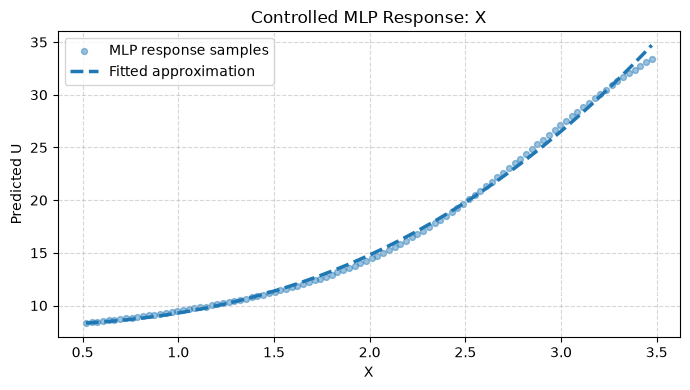

x: predicted_u = 1.18430 * x^2.49873 + 8.10674
Approximation RMSE: 0.35524; R2: 0.99791


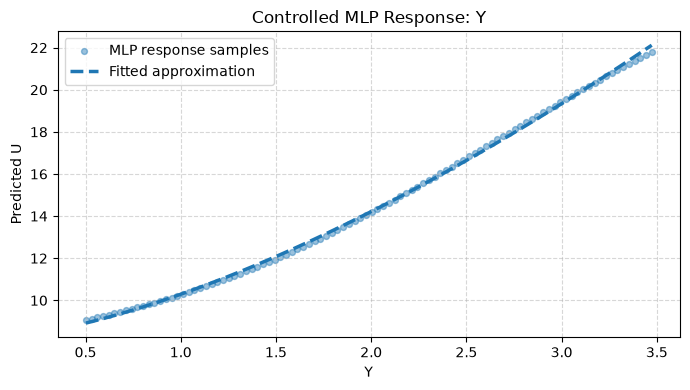

y: predicted_u = 2.10976 * y^1.51622 + 8.18019
Approximation RMSE: 0.10723; R2: 0.99925


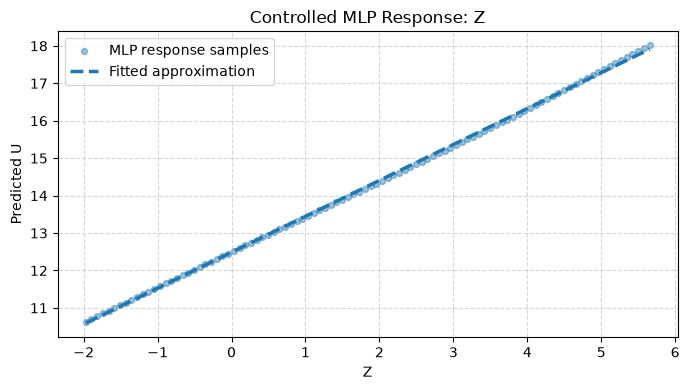

z: predicted_u = 0.95959 * z + 12.48597
Approximation RMSE: 0.03832; R2: 0.99968
Approximations to the three controlled MLP response curves:


,feature,fit_type,coefficient,exponent,slope,offset,fit_RMSE,fit_R2
0,x,power law,1.184298,2.498729,NaN,8.106739,0.355240,0.997914
1,y,power law,2.109763,1.516216,NaN,8.180195,0.107226,0.999249
2,z,linear,NaN,NaN,0.959588,12.485972,0.038323,0.999677


In [18]:
bonus_results = []


def one_variable_power_law(values, coefficient, exponent, offset):
    values = np.asarray(values, dtype=float)
    return coefficient * np.power(values, exponent) + offset


def one_variable_linear(values, slope, offset):
    values = np.asarray(values, dtype=float)
    return slope * values + offset


for feature_name in feature_names:
    feature_values, predictions = controlled_curves[feature_name]
    feature_values = np.asarray(feature_values, dtype=float).ravel()
    predictions = np.asarray(predictions, dtype=float).ravel()

    valid_mask = np.isfinite(feature_values) & np.isfinite(predictions)
    x_fit = feature_values[valid_mask]
    y_fit = predictions[valid_mask]

    if len(x_fit) < 3 or np.ptp(x_fit) == 0:
        print(f"Skipping {feature_name}: insufficient valid data.")
        continue

    if feature_name in ("x", "y"):
        fit_function = one_variable_power_law
        initial_guess = [1.0, 1.5, float(np.mean(y_fit))]
        parameter_bounds = (
            [-np.inf, 0.1, -np.inf],
            [np.inf, 5.0, np.inf],
        )
    else:
        fit_function = one_variable_linear
        initial_guess = [0.0, float(np.mean(y_fit))]
        parameter_bounds = (-np.inf, np.inf)

    try:
        parameters, _ = curve_fit(
            fit_function,
            x_fit,
            y_fit,
            p0=initial_guess,
            bounds=parameter_bounds,
            maxfev=20000,
        )
        fitted_values = fit_function(x_fit, *parameters)
        fit_rmse = float(np.sqrt(mean_squared_error(y_fit, fitted_values)))
        fit_r2 = float(r2_score(y_fit, fitted_values))

        if feature_name in ("x", "y"):
            coefficient, exponent, offset = parameters
            result = {
                "feature": feature_name,
                "fit_type": "power law",
                "coefficient": float(coefficient),
                "exponent": float(exponent),
                "slope": np.nan,
                "offset": float(offset),
                "fit_RMSE": fit_rmse,
                "fit_R2": fit_r2,
            }
            equation_text = (
                f"predicted_u = {coefficient:.5f} * "
                f"{feature_name}^{exponent:.5f} + {offset:.5f}"
            )
        else:
            slope, offset = parameters
            result = {
                "feature": feature_name,
                "fit_type": "linear",
                "coefficient": np.nan,
                "exponent": np.nan,
                "slope": float(slope),
                "offset": float(offset),
                "fit_RMSE": fit_rmse,
                "fit_R2": fit_r2,
            }
            equation_text = (
                f"predicted_u = {slope:.5f} * z + {offset:.5f}"
            )

        bonus_results.append(result)

        plt.figure(figsize=(7, 4))
        plt.scatter(x_fit, y_fit, s=18, alpha=0.45, label="MLP response samples")
        plt.plot(x_fit, fitted_values, "--", linewidth=2.5, label="Fitted approximation")
        plt.title(f"Controlled MLP Response: {feature_name.upper()}")
        plt.xlabel(feature_name.upper())
        plt.ylabel("Predicted U")
        plt.legend()
        plt.grid(True, linestyle="--", alpha=0.5)
        plt.tight_layout()
        plt.show()

        print(f"{feature_name}: {equation_text}")
        print(f"Approximation RMSE: {fit_rmse:.5f}; R2: {fit_r2:.5f}")

    except (RuntimeError, ValueError, FloatingPointError) as error:
        print(f"Could not fit {feature_name}: {error}")


bonus_df = pd.DataFrame(bonus_results)
print("Approximations to the three controlled MLP response curves:")
display(bonus_df)


<div dir="rtl">

### Bonus 3 — تحلیل روند و محدودیت نتیجه‌گیری

برای توصیف عددی منحنی‌های کنترل‌شده، از خانواده‌ی تابع متناسب با شکل هر ورودی استفاده می‌کنیم:

- برای `x` و `y`، یک تقریب توانی از فرم \(\hat u(t)=a t^p+b\) برازش می‌شود.
- برای `z`، یک تقریب خطی از فرم \(\hat u(z)=cz+d\) برازش می‌شود.

این روابط فقط تقریب منحنی پیش‌بینی‌شده‌ی MLP هستند و نباید آن‌ها را معادله‌ی دقیق مولد داده دانست. مقدار \(R^2\) و RMSE در جدول نشان می‌دهد هر تقریب تا چه اندازه شکل منحنی MLP را بازسازی می‌کند؛ این معیارها عملکرد MLP روی داده‌ی آزمون نیستند.

محدودیت‌ها: این منحنی‌ها فقط وقتی دو متغیر دیگر روی میانگین Training ثابت‌اند معتبرند؛ اثرهای متقابل بین ویژگی‌ها را کامل نشان نمی‌دهند. همچنین منحنی‌ها رفتار مدل را نشان می‌دهند، نه حقیقت قطعی طبیعت مسئله. از روابط برازش‌شده نباید خارج از محدوده‌ی Training برون‌یابی کرد.

</div>

<div dir="rtl">

## بخش ۸: تحویل، گزارش و ارائه

### 8.2 — کنترل کیفیت Notebook و فایل‌های تحویلی

این Notebook شامل داده‌ی اختصاصی تولیدشده، بررسی کیفیت داده، EDA، تقسیم و مقیاس‌بندی، حداقل پنج آزمایش، جدول مقایسه‌ی Validation، انتخاب مدل، ارزیابی Test، تحلیل روابط و بخش امتیازی است. برای تحویل نهایی بهتر است این Notebook از ابتدا تا انتها اجرا شود و خروجی‌ها ذخیره شوند. فایل CSV اختصاصی نیز باید همراه Notebook نگهداری شود تا اجرای مجدد قابل تکرار باشد.

بخش ارائه‌ی شفاهی و پرسش زنده در این پاسخ‌نامه نمره‌دهی نشده‌اند؛ این بخش‌ها باید جداگانه در جلسه‌ی ارائه ارزیابی شوند.

### جمع‌بندی نهایی

مدل نهایی بر اساس Validation RMSE انتخاب شد و سپس فقط یک‌بار روی Test ارزیابی شد. معیارهای MAE و RMSE اندازه‌ی خطا را در واحد خروجی نشان می‌دهند و R² نسبت به پیش‌بینی میانگین، کیفیت توضیح تغییرات خروجی را خلاصه می‌کند. تحلیل کنترل‌شده نیز کمک می‌کند اثر هر ورودی را در حضور دو ورودی ثابت بررسی کنیم؛ با این حال، این تحلیل به‌تنهایی رابطه‌ی علّی یا فرمول دقیق مولد داده را اثبات نمی‌کند.

</div>